# MaintainGov · UC01 — Analisis feedback dari ZIP sampai artefak model
**Kelompok 5 · Gerard · Sprint 1/Week 10–11 · notebook eksperimen v1.2 · 18 Oktober 2026**

Notebook ini menerima **satu ZIP** yang berisi CSV ulasan Tangerang Live, kamus
sentimen positif/negatif, dan slang. Jalankan sel berurutan. CPU cukup untuk
eksperimen TF-IDF dan model linear; GPU tidak diperlukan pada alur ini.

**Cakupan:** audit → EDA → normalisasi → sentimen lexicon → anotasi → fitur →
split grup → baseline → seleksi fitur → cross-validation → tuning → ablation →
learning curve → holdout → analisis kesalahan → kandidat case → ekspor.

**Makna hasil:** ZIP belum memuat label sentimen manusia. Mode awal melatih
**prediksi label proksi rating** (1–2 negatif, 3 netral, 4–5 positif). Skor model
terhadap proksi **belum membuktikan kualitas sentimen manusia**. Unggah anotasi
manusia untuk mengganti target. Kategori maintenance, severity, grouping,
prioritas, dan rekomendasi tetap **draf untuk review**, terpisah dari rating.

Notebook tidak menulis MySQL atau menandai fitur Done. Target UC01 akhirnya
tetap melalui Laravel → FastAPI → penyimpanan case Pending oleh backend.

### Peta baca
1. Setup dan input ZIP (bagian 1–3)
2. Audit, EDA, dan resource bahasa (4–9)
3. Anotasi, fitur dan pembagian data (10–13)
4. Model, tuning dan validasi (14–22)
5. Hasil MaintainGov, handoff dan download (23–28)

Buka melalui **File → Upload notebook**, lalu pilih **Runtime → Run all**.
Sel pertama meminta ZIP; tahap berikutnya berjalan berurutan hingga ekspor.

### Cara menjalankan
1. Unggah notebook ini ke Google Colab dan gunakan runtime Python 3.13 dengan CPU.
2. Pilih **Runtime → Run all** dan unggah ZIP saat dialog muncul.
3. Tunggu analisis selesai. Grafik, tabel dan pemeriksaan muncul di setiap tahap.
4. Unduh `MaintainGov_hasil_lengkap.zip` yang ditawarkan pada akhir proses.

Paket lengkap memuat evidence agregat dan artefak privat. Simpan salinan notebook
dengan output melalui menu File di Colab. Hasil contoh yang tersimpan akan
diganti saat notebook dijalankan ulang.


## 1. Tujuan, tanggung jawab, dan batas keputusan

| Hasil | Tugas Gerard | Penerima/reviewer |
|---|---|---|
| Mapping, sampel, label, resource dan aturan | W10-03 | Demas + Valisha |
| Analisis per ulasan, grouping dan rekomendasi | W10-07, UC01 | Hanif + Demas |
| Metode dan keterlacakan artefak UC01 | W10-14 | Demas |
| Kontrak layanan dan adapter | Handoff ke W10-08 | Hanif |
| Persistensi case Pending | Handoff ke W10-09 | Demas |

### Asumsi yang memengaruhi hasil
- Satu record adalah satu ulasan. ID berbeda dengan teks sama tetap dihitung
  sebagai ulasan berbeda; teks identik tidak boleh menyeberangi split ML.
- Tanggal sumber tidak memiliki zona waktu. Data historis bukan daftar masalah
  yang pasti masih aktif. Jumlah ulasan bukan jumlah pengguna unik.
- Akurasi dan F1 proksi rating, agreement lexicon, kualitas kategori, dan kualitas
  severity adalah pengukuran berbeda. Tidak ada label manusia yang dibuat otomatis.
- Aturan konflik kamus dan formula prioritas dalam notebook merupakan usulan D05.
  Keputusan kelompok/PO, kualitas yang diterima, dan lisensi Kaggle masih perlu dicatat.
- Sumber kebutuhan: SRS FR-UC01-01..18, BR-04; MASTERPLAN dan WEEK10_EXECUTION.
  Eksperimen tambahan tidak otomatis menambah poin fitur atau menutup sprint.

### 1.1 Pertanyaan yang dijawab dan bukti yang diperiksa

| Tahap | Pertanyaan | Hasil yang diperiksa |
|---|---|---|
| Audit | Apakah struktur dan isi data layak diproses? | Jumlah valid/karantina, hash, kolom dan konflik resource |
| EDA | Apakah kelas timpang, teks berulang, dan periode tidak merata? | Rating, waktu, panjang, dan kelompok teks |
| Feature engineering | Informasi teks apa yang dipakai tanpa membocorkan rating? | Normalisasi, n-gram kata/karakter, enam fitur bentuk teks |
| Feature selection | Apakah pengurangan dimensi membantu? | Chi-square di dalam fold dan ablation |
| Training/tuning | Model mana bekerja lebih baik daripada mayoritas? | Grouped CV, pencarian parameter dan gap train/validation |
| Holdout | Bagaimana model terpilih bekerja pada grup yang disisihkan? | Precision/recall/F1, confusion matrix, bootstrap dan error analysis |
| MaintainGov | Bagaimana hasil menjadi masukan case yang dapat direview? | Aturan domain, anggota case, usulan prioritas dan payload riset |
| Handoff | Apakah file model benar-benar bisa dipakai ulang? | Reload dalam proses baru, prediksi sintetis, validitas JSON dan ZIP |

Semua tahap dapat berjalan secara teknis meskipun hasil model masih lemah.
Kriteria penerimaan kualitas harus disepakati dari kebutuhan dan label manusia;
notebook tidak menetapkan angka kelulusan akademik yang tidak diberikan.

## 2. Input dan persiapan otomatis
Pilih **Runtime → Run all**, lalu unggah satu ZIP dataset. Lingkungan analisis
disiapkan secara terpisah agar paket NumPy bawaan Colab tidak tercampur dengan
paket eksperimen. Tidak perlu mengubah sel instalasi atau restart manual.

Saat pertama dijalankan, pemasangan paket memerlukan koneksi internet dan waktu
tambahan. Setiap sel analisis menampilkan hasil langsung di notebook. Setelah
seluruh tahap selesai, satu ZIP hasil lengkap otomatis ditawarkan untuk diunduh.


In [2]:
import atexit
import importlib.metadata
import io
import json
import os
from pathlib import Path
import queue
import subprocess
import sys
import tempfile
import time
import venv
from IPython.display import display, clear_output
from jupyter_client import BlockingKernelClient

PACKAGES = {
    "numpy": "2.2.6", "pandas": "2.2.3", "scipy": "1.15.3",
    "scikit-learn": "1.6.1", "matplotlib": "3.10.3",
    "seaborn": "0.13.2", "joblib": "1.5.1",
}
if not (3, 10) <= sys.version_info[:2] < (3, 14):
    raise RuntimeError("Gunakan runtime Python 3.10–3.13.")
if "_mg_close" in globals():
    _mg_close()

_mg_input_path = os.getenv("MAINTAINGOV_ZIP", "")
_mg_run_dir = Path(os.getenv("MAINTAINGOV_OUTPUT") or tempfile.mkdtemp(prefix="maintain_gov_run_")).resolve()
_mg_run_dir.mkdir(parents=True, exist_ok=True)
if not _mg_input_path:
    from google.colab import files
    _mg_uploaded = files.upload()
    _mg_candidates = [name for name in _mg_uploaded if name.lower().endswith(".zip")]
    if len(_mg_candidates) != 1:
        raise ValueError("Unggah tepat satu ZIP dataset.")
    _mg_input_path = str(_mg_run_dir / "input_dataset.zip")
    Path(_mg_input_path).write_bytes(_mg_uploaded[_mg_candidates[0]])

_mg_worker_override = os.getenv("MAINTAINGOV_WORKER_PYTHON", "")
if _mg_worker_override:
    _mg_python = Path(_mg_worker_override).resolve()
else:
    _mg_env = Path(tempfile.gettempdir()) / f"maintain_gov_env_py{sys.version_info.major}{sys.version_info.minor}_v12"
    _mg_python = _mg_env / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
    if not _mg_python.is_file():
        print("Menyiapkan lingkungan analisis...", flush=True)
        venv.EnvBuilder(with_pip=True).create(_mg_env)

_mg_required = {**PACKAGES, "ipykernel": "7.4.0"}
_mg_version_probe = (
    "import json,importlib.metadata as m; "
    "print(json.dumps({p:m.version(p) for p in " + repr(list(_mg_required)) + "}))"
)
_mg_probe = subprocess.run([str(_mg_python), "-c", _mg_version_probe], capture_output=True, text=True)
try:
    _mg_installed = json.loads(_mg_probe.stdout) if _mg_probe.returncode == 0 else {}
except json.JSONDecodeError:
    _mg_installed = {}
_mg_needed = [f"{package}=={version}" for package, version in _mg_required.items() if _mg_installed.get(package) != version]
if _mg_needed:
    print("Memasang paket analisis pada lingkungan terpisah...", flush=True)
    _mg_pip = subprocess.run([str(_mg_python), "-m", "pip", "install", "--disable-pip-version-check", "-q", *_mg_needed], capture_output=True, text=True)
    if _mg_pip.returncode:
        print(_mg_pip.stderr[-4000:])
        raise RuntimeError("Pemasangan paket analisis gagal. Periksa koneksi dan ruang runtime lalu jalankan Run all kembali.")

_mg_connection = _mg_run_dir / "worker_connection.json"
_mg_log = (_mg_run_dir / "worker_kernel.log").open("w", encoding="utf-8")
_mg_env_vars = os.environ.copy()
for _mg_inherited in ("JPY_PARENT_PID", "JPY_INTERRUPT_EVENT", "IPY_INTERRUPT_EVENT", "PYTHONPATH", "PYTHONHOME"):
    _mg_env_vars.pop(_mg_inherited, None)
_mg_env_vars["PYTHONNOUSERSITE"] = "1"
_mg_env_vars["MAINTAINGOV_ZIP"] = str(Path(_mg_input_path).resolve())
_mg_env_vars["MAINTAINGOV_OUTPUT"] = str(_mg_run_dir)
_mg_env_vars["MPLBACKEND"] = "module://matplotlib_inline.backend_inline"
_mg_env_vars["PYTHONIOENCODING"] = "utf-8"
_mg_process = subprocess.Popen([
    str(_mg_python), "-m", "ipykernel_launcher", "-f", str(_mg_connection),
    "--IPKernelApp.ip=127.0.0.1", "--HistoryManager.hist_file=:memory:"
], env=_mg_env_vars, stdout=_mg_log, stderr=_mg_log)
_mg_client = None
def _mg_close():
    client = globals().get("_mg_client")
    process = globals().get("_mg_process")
    if client is not None:
        client.stop_channels()
    if process is not None and process.poll() is None:
        process.terminate()
        try:
            process.wait(timeout=10)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait(timeout=10)
    log = globals().get("_mg_log")
    if log is not None and not log.closed:
        log.close()
atexit.register(_mg_close)
_mg_deadline = time.monotonic() + 90
while True:
    if _mg_connection.is_file():
        try:
            _mg_connection_data = json.loads(_mg_connection.read_text(encoding="utf-8"))
            if "shell_port" in _mg_connection_data and "iopub_port" in _mg_connection_data:
                break
        except (OSError, json.JSONDecodeError):
            pass
    if _mg_process.poll() is not None or time.monotonic() > _mg_deadline:
        _mg_close()
        raise RuntimeError("Lingkungan analisis tidak dapat dimulai. Jalankan Run all kembali.")
    time.sleep(.1)
_mg_client = BlockingKernelClient(connection_file=str(_mg_connection))
_mg_client.load_connection_file()
_mg_client.start_channels()
_mg_ready = False
_mg_ready_deadline = time.monotonic() + 90
while time.monotonic() < _mg_ready_deadline:
    try:
        _mg_client.wait_for_ready(timeout=5)
    except (RuntimeError, TimeoutError):
        if _mg_process.poll() is not None:
            _mg_close()
            raise RuntimeError("Proses analisis berhenti saat persiapan.")
        time.sleep(.2)
    else:
        _mg_ready = True
        break
if not _mg_ready:
    _mg_close()
    raise RuntimeError("Persiapan analisis melewati batas waktu.")

def _mg_run(line, source):
    if _mg_process.poll() is not None:
        raise RuntimeError("Sesi analisis berakhir. Jalankan Run all untuk memulai sesi baru.")
    request_id = _mg_client.execute(source, store_history=False)
    failure = None
    deadline = time.monotonic() + 1800
    while time.monotonic() < deadline:
        try:
            message = _mg_client.get_iopub_msg(timeout=1)
        except queue.Empty:
            if _mg_process.poll() is not None:
                raise RuntimeError("Proses analisis berhenti sebelum sel selesai.")
            continue
        if message.get("parent_header", {}).get("msg_id") != request_id:
            continue
        kind, content = message["msg_type"], message["content"]
        if kind == "stream":
            print(content["text"], end="", flush=True)
        elif kind in {"display_data", "execute_result"}:
            display(content["data"], metadata=content.get("metadata", {}), raw=True)
        elif kind == "clear_output":
            clear_output(wait=content.get("wait", False))
        elif kind == "error":
            failure = "\n".join(content.get("traceback", [])) or content.get("evalue", "Error analisis")
        elif kind == "status" and content.get("execution_state") == "idle":
            if failure:
                raise RuntimeError(failure)
            return
    raise TimeoutError("Sel analisis melewati batas 30 menit.")
get_ipython().register_magic_function(_mg_run, magic_kind="cell", magic_name="maintain_gov")
print("ZIP diterima. Lingkungan analisis siap; proses dilanjutkan otomatis.")

ZIP diterima. Lingkungan analisis siap; proses dilanjutkan otomatis.


In [3]:
%%maintain_gov
import importlib.metadata as metadata
import subprocess, sys
PACKAGES = {'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.15.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.3', 'seaborn': '0.13.2', 'joblib': '1.5.1'}
import os, io, csv, re, json, time, hashlib, platform, shutil, zipfile, unicodedata
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown
from scipy import sparse
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import (StratifiedGroupKFold, cross_validate,
                                      RandomizedSearchCV, learning_curve)
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score, silhouette_score,
    cohen_kappa_score)
from sklearn.cluster import AgglomerativeClustering
import joblib
from threadpoolctl import threadpool_limits
THREAD_LIMIT = threadpool_limits(limits=2)

### 2.0 Pemeriksaan lingkungan analisis
Versi paket, operasi NumPy, struktur sparse SciPy dan tabel Pandas diperiksa
pada lingkungan analisis sebelum dataset diproses.


In [4]:
%%maintain_gov
runtime_smoke_checks = {
    "numpy_strings": np.strings.lower(np.array(["OK", "MaintainGov"])).tolist() == ["ok", "maintaingov"],
    "numpy_numeric": bool(np.isclose(np.mean([1.0, 2.0, 3.0]), 2.0)),
    "scipy_sparse": sparse.csr_matrix([[0, 1], [2, 0]]).nnz == 2,
    "pandas_frame": bool(pd.DataFrame({"x": [1, 2]}).x.sum() == 3),
}
runtime_versions = {name: metadata.version(name) for name in [*PACKAGES, "threadpoolctl", "pillow"]}
display(pd.Series(runtime_versions, name="versi aktual").to_frame())
display(pd.Series(runtime_smoke_checks, name="passed").to_frame())
assert all(runtime_smoke_checks.values()), "Pemeriksaan awal gagal; perbaiki runtime sebelum lanjut."

,versi aktual
numpy,2.2.6
pandas,2.2.3
scipy,1.15.3
scikit-learn,1.6.1
matplotlib,3.10.3
seaborn,0.13.2
joblib,1.5.1
threadpoolctl,3.7.0
pillow,13.0.0


,passed
numpy_strings,True
numpy_numeric,True
scipy_sparse,True
pandas_frame,True


### 2.1 Parameter eksperimen
Default memproses seluruh dataset. `SEARCH_ITER=12` membatasi biaya tuning;
naikkan setelah alur pertama berhasil. Test holdout tidak dipakai untuk memilih
parameter. Mengubah fitur sesudah membaca hasil test memerlukan test baru.

`LABEL_MODE="rating_proxy"` berjalan langsung dengan ZIP asli. Untuk evaluasi
sentimen manusia, isi template anotasi, masukkan `annotations.csv` ke ZIP, lalu ubah menjadi `human` sebelum Run all. Mode human memerlukan
jumlah kelompok berlabel yang cukup; notebook akan menghentikan pelatihan
dengan pesan jelas jika syarat belum terpenuhi.

| Parameter | Fungsi dan kapan diubah |
|---|---|
| `SEED=42` | Mengulang pemilihan partisi dan pencarian parameter; bukan jaminan hasil identik lintas platform |
| `LABEL_MODE` | `rating_proxy` untuk ZIP awal; `human` hanya setelah anotasi sungguhan selesai direview |
| `CV_FOLDS=3` | Validasi silang pada data train; otomatis dibatasi jumlah grup per kelas |
| `HOLDOUT_FOLDS=5` | Menyisihkan sekitar satu dari lima fold grup; proporsi baris dapat berbeda |
| `SEARCH_ITER=12` | Banyak konfigurasi tuning, bukan jumlah epoch; seluruh data valid tetap diproses |
| `BOOTSTRAPS=300` | Resampling grup pada test untuk interval macro-F1 model tetap |
| `RUN_LEARNING_CURVE` | Menjalankan diagnostik ukuran train; dapat memerlukan beberapa fit tambahan |
| `RUN_GROUPING` | Mengaktifkan pengelompokan kandidat issue; bukan pelatihan model sentimen |
| `N_JOBS=1` | Membatasi kerja paralel dan penggunaan RAM Colab |
| Unduhan hasil | Satu ZIP lengkap ditawarkan otomatis pada sel terakhir; tidak perlu mengubah parameter download |

Selesaikan satu konfigurasi sebelum membuka holdout. Perubahan setelah membaca
test menjadikan test bagian proses pengembangan; diperlukan test independen baru.
Setiap Run all membuat folder hasil baru agar artefak lama tidak tercampur.
Jalankan dari awal ketika mengubah konfigurasi. Di luar Colab folder dapat ditentukan melalui environment.

In [5]:
%%maintain_gov
SEED = 42
LABEL_MODE = "rating_proxy"
CV_FOLDS = 3
HOLDOUT_FOLDS = 5
SEARCH_ITER = 12
N_JOBS = 1
BOOTSTRAPS = 300
RUN_LEARNING_CURVE = True
RUN_GROUPING = True
DOWNLOAD_ARTIFACTS = True
ANNOTATION_PATH = os.getenv("MAINTAINGOV_ANNOTATIONS", "")
SOURCE_URL = ""
SOURCE_LICENSE = "belum dikonfirmasi"
RUN_STARTED = datetime.now(timezone.utc).isoformat()
default_output = "maintain_gov_run_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
OUTPUT = Path(os.getenv("MAINTAINGOV_OUTPUT", default_output)).resolve()
PUBLIC = OUTPUT / "evidence_aggregates"
PRIVATE = OUTPUT / "private_artifacts"
FIGURES = PUBLIC / "figures"
for directory in (PUBLIC, PRIVATE, FIGURES):
    directory.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
pd.set_option("display.max_rows", 14)
pd.set_option("display.max_colwidth", 65)
COLORS = {"negative": "#C06B35", "neutral": "#9A7B2E", "positive": "#3478A8",
          "mixed": "#8A6398", "undetermined": "#697582"}
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans",
    rc={"axes.spines.top": False, "axes.spines.right": False,
        "axes.titlesize": 14, "axes.labelsize": 11, "figure.dpi": 110,
        "grid.alpha": .22, "axes.titlepad": 14})
def save_show(name, fig=None):
    fig = fig or plt.gcf()
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
def note(text):
    display(Markdown(text))
print("Mode:", LABEL_MODE, "| Seed:", SEED, "| Python:", platform.python_version())
if LABEL_MODE not in {"rating_proxy", "human"}:
    raise ValueError("LABEL_MODE harus rating_proxy atau human.")
if CV_FOLDS < 2 or HOLDOUT_FOLDS < 2 or SEARCH_ITER < 1 or BOOTSTRAPS < 20:
    raise ValueError("Gunakan CV/HOLDOUT >=2, SEARCH_ITER >=1, BOOTSTRAPS >=20.")
print("Folder hasil run ini:", OUTPUT.name)

Mode: rating_proxy | Seed: 42 | Python: 3.13.16
Folder hasil run ini: artifacts


## 3. Inventaris ZIP yang diunggah
ZIP yang dipilih pada awal Run all dibaca pada tahap ini. Tidak ada dialog
unggah kedua pada mode proksi. Empat file data dikenali dari nama, sehingga
ZIP boleh memuat satu direktori induk. Arsip diperlakukan sebagai data dan
tidak diekstrak melalui `extractall()`. Inventaris menampilkan nama file,
ukuran dan hash sumber; nama reviewer tidak ditampilkan.


### 3.1 Struktur input yang diterima

| File/kolom | Tipe | Aturan |
|---|---|---|
| `Review Aplikasi Tangerang Live.csv` | CSV UTF-8, koma | Nama file mengikuti ZIP yang telah diperiksa |
| `reviewId` | Teks | Wajib, tidak kosong, unik dalam data yang digunakan |
| `Review Teks` | Teks | Wajib; kutip, koma, emoji dan newline didukung parser CSV |
| `rating` | Bilangan 1–5 | Wajib untuk struktur dataset ini; pembentuk target hanya pada mode proksi |
| `date` | `YYYY-MM-DD HH:MM:SS` | Wajib; zona waktu belum disediakan sumber |
| `userName` / `thumbsUpCount` | Metadata opsional | Bukan fitur sentimen; identitas tidak ditampilkan |
| `positive.tsv` / `negative.tsv` | TSV, term + bobot | Resource sentimen; konflik diaudit sebelum dipakai |
| `slang.csv` | CSV, titik koma | Resource normalisasi dua kolom |
| `annotations.csv` | CSV UTF-8, opsional | Label reviewed untuk mode human; bukan keluaran prediksi model |

Dataset sumber lain perlu adapter/pemetaan kolom. Rating yang tidak tersedia
tidak boleh dibuat-buat. Untuk saat ini notebook ditujukan pada ZIP kelompok;
tidak melakukan scraping atau menggabungkan aplikasi berbeda secara otomatis.

In [6]:
%%maintain_gov
def load_dataset_zip(payload):
    expected = {"Review Aplikasi Tangerang Live.csv", "negative.tsv", "positive.tsv", "slang.csv"}
    selected, records = {}, []
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        if sum(info.file_size for info in archive.infolist()) > 64 * 1024**2:
            raise ValueError("Ukuran terurai di atas batas notebook 64 MiB; tinjau arsip dahulu.")
        for info in archive.infolist():
            if info.is_dir():
                continue
            parts = PurePosixPath(info.filename.replace("\\", "/"))
            if ".." in parts.parts or parts.is_absolute() or ":" in parts.parts[0] or info.flag_bits & 1:
                raise ValueError("Path arsip tidak aman atau file terenkripsi.")
            base = parts.name
            records.append({"file": base, "bytes": info.file_size})
            if base in expected or base == "annotations.csv":
                if base in selected:
                    raise ValueError(f"Nama file ganda dalam ZIP: {base}")
                selected[base] = archive.read(info)
    missing = expected - selected.keys()
    if missing:
        raise ValueError(f"File wajib tidak ditemukan: {sorted(missing)}")
    return selected, records

zip_path = os.getenv("MAINTAINGOV_ZIP", "")
if zip_path:
    zip_bytes = Path(zip_path).read_bytes()
else:
    try:
        from google.colab import files
    except ImportError as exc:
        raise RuntimeError("Di luar Colab, isi environment MAINTAINGOV_ZIP dengan path ZIP.") from exc
    uploaded = files.upload()
    candidates = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(candidates) != 1:
        raise ValueError("Unggah tepat satu file ZIP dataset.")
    zip_bytes = uploaded[candidates[0]]
SOURCE_SHA = hashlib.sha256(zip_bytes).hexdigest()
members, inventory = load_dataset_zip(zip_bytes)
display(pd.DataFrame(inventory))
print("SHA-256 ZIP:", SOURCE_SHA)

,file,bytes
0,Review Aplikasi Tangerang Live.csv,1004486
1,negative.tsv,82775
2,positive.tsv,41462
3,slang.csv,299613


SHA-256 ZIP: 243ac29f1907baade790589ced4f331fc4e6d32e78691ee8477541aacdf1bdcf


## 4. Validasi struktur, kualitas, dan karantina
Parser memakai pemisah eksplisit: CSV ulasan koma, lexicon tab, slang titik koma.
Kutip, koma, dan newline di dalam teks ditangani parser CSV. Record salah
dikarantina dengan alasan; tidak diisi nilai tebakan. ID berulang dikeluarkan
seluruhnya dari eksperimen agar asal data tidak ambigu. Ulasan ber-ID berbeda
dengan teks berulang dipertahankan. Data mentah dan karantina tetap privat.

In [7]:
%%maintain_gov
def read_table(raw, delimiter):
    reader = csv.reader(io.StringIO(raw.decode("utf-8-sig"), newline=""),
                        delimiter=delimiter, strict=True)
    try:
        header = next(reader)
    except StopIteration as exc:
        raise ValueError("File tabel kosong: header tidak tersedia.") from exc
    if len(header) != len(set(header)):
        raise ValueError("Nama kolom berulang.")
    good, bad = [], []
    for number, row in enumerate(reader, 1):
        if len(row) != len(header):
            bad.append({"record": number, "reason": "field_count"})
        else:
            good.append(row)
    return pd.DataFrame(good, columns=header), pd.DataFrame(bad, columns=["record", "reason"])
raw, malformed = read_table(members["Review Aplikasi Tangerang Live.csv"], ",")
required = {"reviewId", "Review Teks", "rating", "date"}
if not required <= set(raw):
    raise ValueError(f"Kolom wajib kurang: {required - set(raw)}")
raw["record_number"] = np.arange(1, len(raw) + 1)
raw["reviewId"] = raw["reviewId"].str.strip()
raw["rating_value"] = pd.to_numeric(raw["rating"], errors="coerce")
raw["date_value"] = pd.to_datetime(raw["date"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
checks = pd.DataFrame({
    "blank_id": raw["reviewId"].eq(""),
    "blank_text": raw["Review Teks"].str.strip().eq(""),
    "invalid_rating": ~raw["rating"].str.strip().isin(["1", "2", "3", "4", "5"]),
    "invalid_date": raw["date_value"].isna(),
    "duplicate_id": raw["reviewId"].duplicated(keep=False),
})
if "thumbsUpCount" in raw:
    checks["invalid_thumbs"] = ~raw["thumbsUpCount"].str.fullmatch(r"[0-9]+")
bad_rows = checks.any(axis=1)
quarantine = raw.loc[bad_rows].copy()
quarantine["reasons"] = [",".join(row.index[row]) for _,row in checks.loc[bad_rows].iterrows()]
quarantine.to_csv(PRIVATE / "quarantine.csv", index=False)
malformed.to_csv(PRIVATE / "malformed_records.csv", index=False)
df = raw.loc[~bad_rows].copy().reset_index(drop=True)
df["rating_value"] = df["rating_value"].astype(int)
assert len(df) and df["reviewId"].is_unique
audit = {"correct_width_records": len(raw), "malformed_records": len(malformed),
         "quarantined_records": len(quarantine), "usable_records": len(df),
         "invalid_field_counts": {k: int(v) for k, v in checks.sum().items()},
         "source_sha256": SOURCE_SHA, "timezone": "not supplied"}
display(pd.Series(audit["invalid_field_counts"], name="record bermasalah").to_frame())
print(f"Dipakai {len(df):,} ulasan; karantina {len(quarantine):,}; struktur salah {len(malformed):,}.")

,record bermasalah
blank_id,0
blank_text,0
invalid_rating,0
invalid_date,0
duplicate_id,0
invalid_thumbs,0


Dipakai 7,149 ulasan; karantina 0; struktur salah 0.


### 4.1 Smoke test parser dan penjagaan ZIP
Contoh di bawah adalah fixture sintetis, bukan teks dari dataset. Input yang
memang tidak valid dianggap lulus pengujian ketika ditolak dengan benar.
Kutip/newline diuji sebagai satu record agar kolom rating tidak bergeser.

In [8]:
%%maintain_gov
input_smoke_checks = {}
quoted = b'id,text,rating\n1,"contoh, dengan koma\ndan baris baru",5\n'
quoted_table, quoted_bad = read_table(quoted, ",")
input_smoke_checks["quoted_comma_newline"] = len(quoted_table) == 1 and len(quoted_bad) == 0 and quoted_table.rating.iloc[0] == "5"
width_table, width_bad = read_table(b'a,b\n1,2,3\n4,5\n', ",")
input_smoke_checks["wrong_width_quarantined"] = len(width_bad) == 1 and len(width_table) == 1
def rejects(callback, expected_error=ValueError):
    try:
        callback()
    except expected_error:
        return True
    return False
input_smoke_checks["duplicate_header_rejected"] = rejects(lambda: read_table(b'a,a\n1,2\n', ","))
input_smoke_checks["empty_table_rejected"] = rejects(lambda: read_table(b'', ","))
def fixture_zip(names):
    buffer = io.BytesIO()
    with zipfile.ZipFile(buffer, "w") as archive:
        for name in names:
            archive.writestr(name, "fixture")
    return buffer.getvalue()
input_smoke_checks["missing_zip_members_rejected"] = rejects(lambda: load_dataset_zip(fixture_zip(["slang.csv"])))
input_smoke_checks["zip_parent_path_rejected"] = rejects(lambda: load_dataset_zip(fixture_zip(["../slang.csv"])))
input_smoke_checks["zip_absolute_path_rejected"] = rejects(lambda: load_dataset_zip(fixture_zip(["/slang.csv"])))
input_smoke_checks["zip_drive_path_rejected"] = rejects(lambda: load_dataset_zip(fixture_zip(["C:/slang.csv"])))
input_smoke_checks["zip_duplicate_basename_rejected"] = rejects(lambda: load_dataset_zip(fixture_zip(["a/slang.csv", "b/slang.csv"])))
display(pd.Series(input_smoke_checks, name="passed").to_frame())
assert all(input_smoke_checks.values()), "Smoke test parser/ZIP gagal."
runtime_smoke_checks.update(input_smoke_checks)

,passed
quoted_comma_newline,True
wrong_width_quarantined,True
duplicate_header_rejected,True
empty_table_rejected,True
missing_zip_members_rejected,True
zip_parent_path_rejected,True
zip_absolute_path_rejected,True
zip_drive_path_rejected,True
zip_duplicate_basename_rejected,True


## 5. EDA — distribusi rating dan kelengkapan
Rating adalah metadata pengalaman pengguna. Distribusinya memberi konteks
ketimpangan kelas proksi; bukan jumlah bug atau tingkat severity.

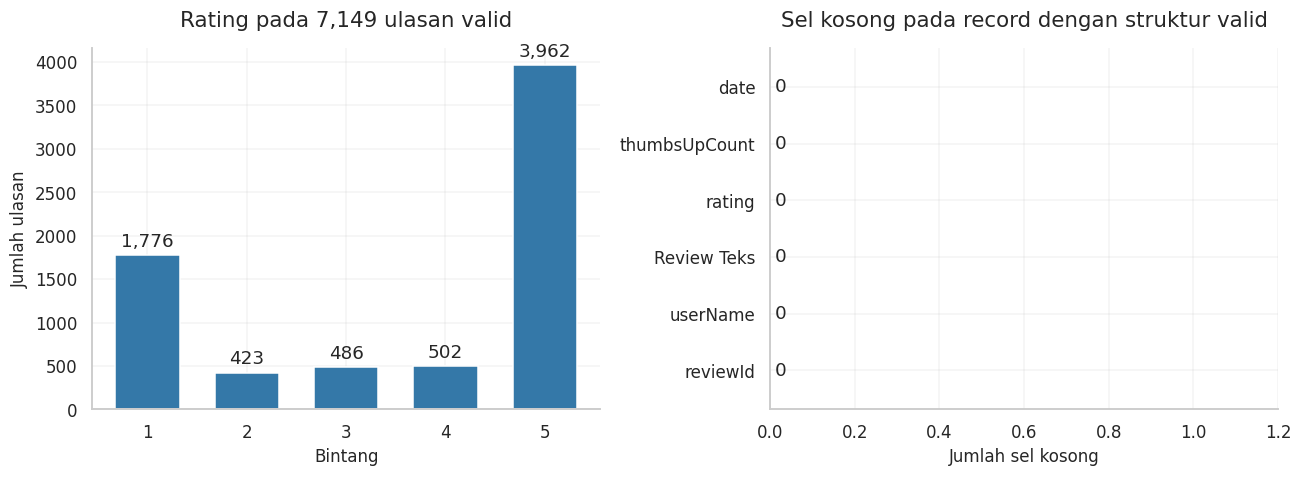

**Pembacaan:** rating terbanyak adalah 5 bintang (3,962 ulasan). Ketimpangan ini menjadi alasan memakai macro-F1 dan balanced accuracy selain accuracy.

In [9]:
%%maintain_gov
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
counts = df["rating_value"].value_counts().reindex(range(1, 6), fill_value=0)
bars = axes[0].bar(counts.index.astype(str), counts.values, color="#3478A8", width=.65)
axes[0].bar_label(bars, labels=[f"{n:,}" for n in counts], padding=3)
axes[0].set(title=f"Rating pada {len(df):,} ulasan valid", xlabel="Bintang", ylabel="Jumlah ulasan")
missing_cells = raw[[c for c in raw if c in {"reviewId","userName","Review Teks","rating","thumbsUpCount","date"}]].apply(lambda col: col.str.strip().eq("").sum())
missing_bars = axes[1].barh(missing_cells.index, missing_cells.values, color="#C06B35")
axes[1].bar_label(missing_bars,padding=3)
axes[1].set(title="Sel kosong pada record dengan struktur valid", xlabel="Jumlah sel kosong")
axes[1].set_xlim(0, max(1, missing_cells.max()) * 1.2)
save_show("01_rating_missing", fig)
note(f"**Pembacaan:** rating terbanyak adalah {counts.idxmax()} bintang ({counts.max():,} ulasan). "
     "Ketimpangan ini menjadi alasan memakai macro-F1 dan balanced accuracy selain accuracy.")

## 6. EDA — waktu, panjang teks, dan pengulangan
Grafik waktu menghitung ulasan dalam snapshot, tanpa mengisi bulan di luar
rentang sebagai nol. Bulan pertama/terakhir dapat parsial. Tidak ada asumsi
zona waktu atau penyebab perubahan jumlah ulasan.

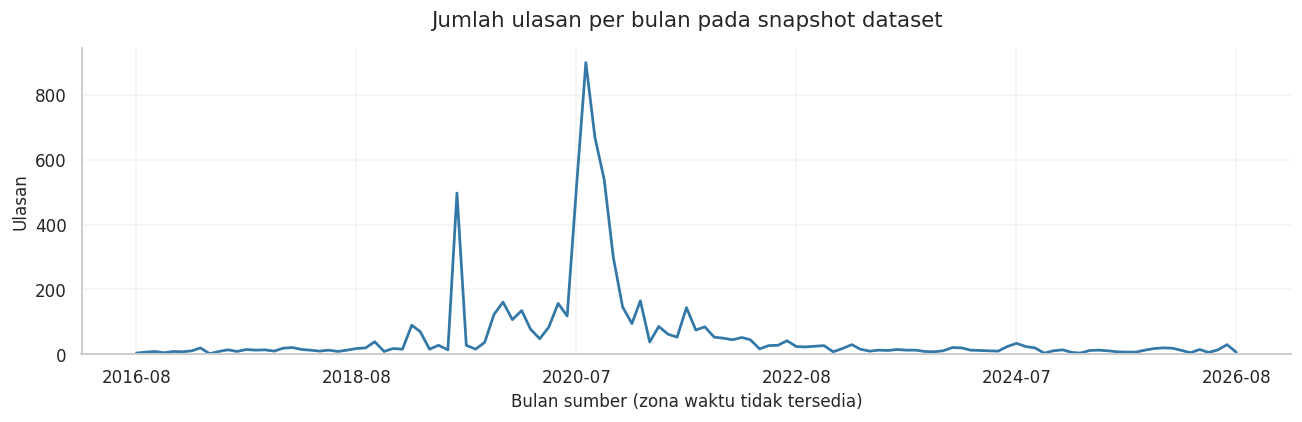

**Cakupan:** 18 Aug 2016–05 Aug 2026. Bulan tanpa record di dalam rentang ditampilkan nol ulasan pada snapshot; bukan bukti tidak ada pengguna.

In [10]:
%%maintain_gov
monthly = df.groupby(df["date_value"].dt.to_period("M")).size()
calendar = pd.period_range(monthly.index.min(), monthly.index.max(), freq="M")
monthly = monthly.reindex(calendar, fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index.to_timestamp(), monthly.values, color="#3478A8", linewidth=1.8)
ax.set(title="Jumlah ulasan per bulan pada snapshot dataset", xlabel="Bulan sumber (zona waktu tidak tersedia)", ylabel="Ulasan")
ax.set_ylim(bottom=0)
ticks = pd.date_range(monthly.index.min().to_timestamp(), monthly.index.max().to_timestamp(), periods=6)
ax.set_xticks(ticks); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
save_show("02_monthly_reviews", fig)
note(f"**Cakupan:** {df.date_value.min():%d %b %Y}–{df.date_value.max():%d %b %Y}. "
     "Bulan tanpa record di dalam rentang ditampilkan nol ulasan pada snapshot; bukan bukti tidak ada pengguna.")

### 6.1 Perubahan komposisi rating antarperiode
Proporsi tahunan membantu melihat perubahan komposisi snapshot. Grafik ini
belum membuktikan penurunan kualitas aplikasi atau perubahan sentimen manusia.
Jumlah ulasan setiap tahun ditampilkan agar tahun dengan sedikit data terbaca.

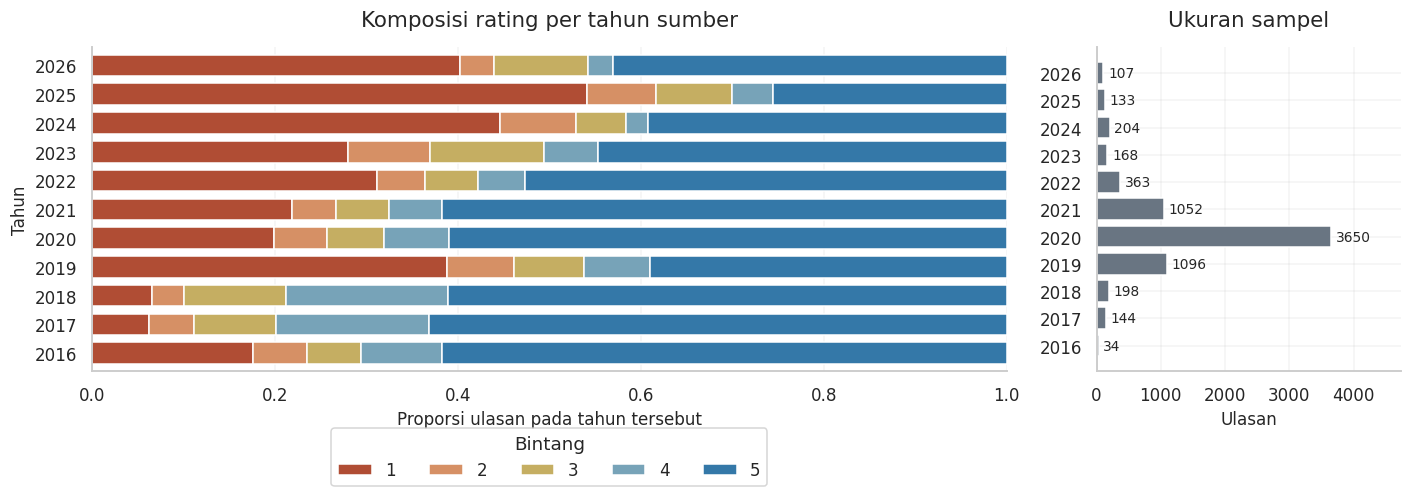

In [11]:
%%maintain_gov
year_counts = pd.crosstab(df.date_value.dt.year, df.rating_value).reindex(columns=range(1, 6), fill_value=0)
year_mix = year_counts.div(year_counts.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [3, 1]})
year_mix.plot.barh(stacked=True, ax=axes[0], color=["#B04D34", "#D69065", "#C5AE62", "#77A3B8", "#3478A8"], width=.75)
axes[0].set(title="Komposisi rating per tahun sumber", xlabel="Proporsi ulasan pada tahun tersebut", ylabel="Tahun", xlim=(0, 1))
axes[0].legend(title="Bintang", ncol=5, loc="upper center", bbox_to_anchor=(.5, -.15))
bars = axes[1].barh(year_counts.index.astype(str), year_counts.sum(axis=1), color="#697582")
axes[1].bar_label(bars, padding=3, fontsize=9)
axes[1].set(title="Ukuran sampel", xlabel="Ulasan", xlim=(0, year_counts.sum(axis=1).max()*1.3))
save_show("18_yearly_rating_mix", fig)

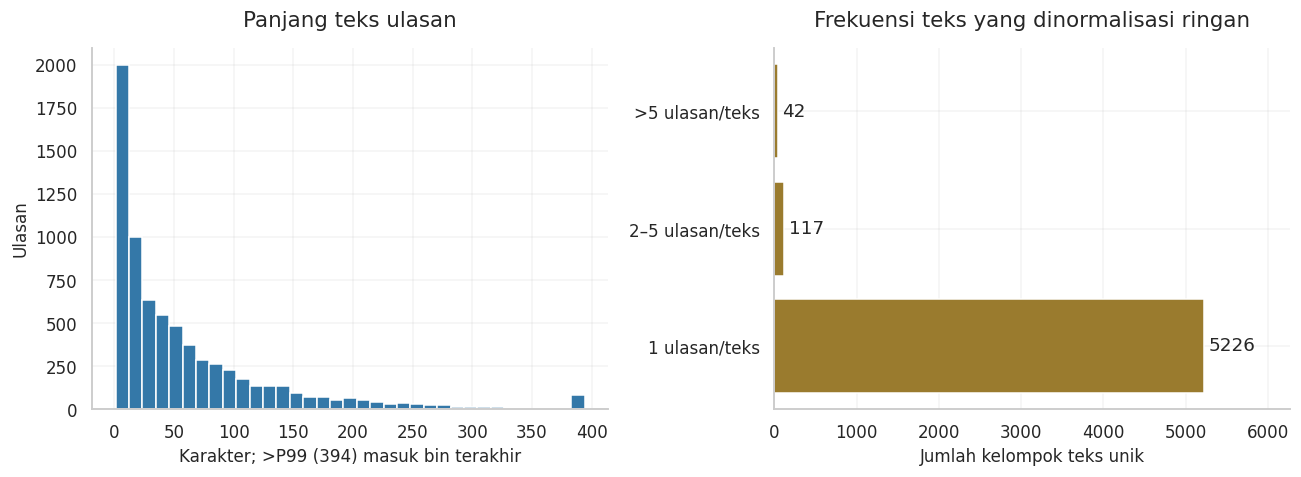

**Pembacaan:** 5,385 teks unik dari 7,149 ulasan; 1,764 ulasan tambahan mempunyai teks sama. Pembatasan P99 hanya untuk grafik, tidak memangkas teks pelatihan.

In [12]:
%%maintain_gov
df["raw_length"] = df["Review Teks"].str.len()
duplicate_key = df["Review Teks"].map(lambda s: " ".join(unicodedata.normalize("NFKC", s).casefold().split()))
text_frequency = duplicate_key.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cutoff = float(df.raw_length.quantile(.99))
axes[0].hist(df.raw_length.clip(upper=cutoff), bins=35, color="#3478A8", edgecolor="white")
axes[0].set(title="Panjang teks ulasan", xlabel=f"Karakter; >P99 ({cutoff:.0f}) masuk bin terakhir", ylabel="Ulasan")
group_sizes = pd.Series({"1 ulasan/teks": int((text_frequency == 1).sum()),
                         "2–5 ulasan/teks": int(text_frequency.between(2,5).sum()),
                         ">5 ulasan/teks": int((text_frequency > 5).sum())})
bars = axes[1].barh(group_sizes.index, group_sizes.values, color="#9A7B2E")
axes[1].bar_label(bars, padding=3)
axes[1].set(title="Frekuensi teks yang dinormalisasi ringan", xlabel="Jumlah kelompok teks unik")
axes[1].set_xlim(0, max(group_sizes.max(),1)*1.2)
save_show("03_length_duplicates", fig)
note(f"**Pembacaan:** {len(text_frequency):,} teks unik dari {len(df):,} ulasan; "
     f"{len(df)-len(text_frequency):,} ulasan tambahan mempunyai teks sama. "
     "Pembatasan P99 hanya untuk grafik, tidak memangkas teks pelatihan.")

## 7. Audit kamus slang dan sentimen
Kamus sumber memiliki key berulang, konflik bobot, dan overlap polaritas.
Kebijakan eksplisit berikut **draf untuk review D05**:

1. Normalisasi key dengan NFKC, casefold, dan spasi.
2. Slang dengan beberapa makna formal **dilewati**; tidak mengambil baris pertama.
   Hanya key satu token yang dipakai normalizer. Override kecil milik proyek
   mempertahankan `tidak/belum/bukan/jangan` dan menyamakan variasi umum.
3. Key sentimen dengan bobot berbeda dalam file yang sama memakai median dari
   **bobot unik**. Bobot negatif/positif diberi tanda sesuai file sumber.
4. Istilah yang hadir pada kedua polaritas **dilewati seluruhnya**, sehingga
   tidak dihitung dua kali. Simpan daftar konflik secara privat untuk kurasi.

Kebijakan ini memungkinkan eksperimen berjalan, bukan bukti kamus sudah benar.

In [13]:
%%maintain_gov
def key_normalize(text):
    return " ".join(unicodedata.normalize("NFKC", str(text)).casefold().split())
slang_table, slang_bad = read_table(members["slang.csv"], ";")
positive_table, pos_bad = read_table(members["positive.tsv"], "	")
negative_table, neg_bad = read_table(members["negative.tsv"], "	")
slang_values = defaultdict(set)
for left, right in slang_table.iloc[:, :2].itertuples(index=False, name=None):
    slang_values[key_normalize(left)].add(key_normalize(right))
slang_conflicts = {key: sorted(values) for key, values in slang_values.items() if len(values) > 1}
SLANG = {key: next(iter(values)) for key, values in slang_values.items()
         if key and len(key.split()) == 1 and len(values) == 1 and next(iter(values))}
NEGATORS = {"tidak", "bukan", "belum", "jangan"}
SLANG.update({"ga":"tidak", "gak":"tidak", "gk":"tidak", "nggak":"tidak", "tdk":"tidak", "lemot":"lambat"})
for negation in NEGATORS:
    SLANG[negation] = negation
def collapse_lexicon(table, sign):
    grouped = defaultdict(set)
    for term, weight in table.iloc[:, :2].itertuples(index=False, name=None):
        grouped[key_normalize(term)].add(abs(float(weight)))
    return {term: sign * float(np.median(sorted(values))) for term, values in grouped.items() if term}, grouped
positive_lex, pos_groups = collapse_lexicon(positive_table, 1)
negative_lex, neg_groups = collapse_lexicon(negative_table, -1)
OVERLAP = set(positive_lex) & set(negative_lex)
LEXICON = {key:value for source in (positive_lex,negative_lex) for key,value in source.items()
           if key not in OVERLAP and value != 0}
resource_audit = pd.DataFrame([
    {"resource":"slang", "records":len(slang_table), "conflicting_keys":len(slang_conflicts)},
    {"resource":"positive", "records":len(positive_table), "conflicting_keys":sum(len(v)>1 for v in pos_groups.values())},
    {"resource":"negative", "records":len(negative_table), "conflicting_keys":sum(len(v)>1 for v in neg_groups.values())},
])
display(resource_audit)
print("Overlap polaritas dilewati:", len(OVERLAP), "| Slang aktif:", len(SLANG), "| Lexicon aktif:", len(LEXICON))
(PRIVATE / "resource_conflicts.json").write_text(json.dumps({"slang":slang_conflicts,"sentiment_overlap":sorted(OVERLAP)},ensure_ascii=False),encoding="utf-8")

,resource,records,conflicting_keys
0,slang,16158,742
1,positive,3609,0
2,negative,6608,3


Overlap polaritas dilewati: 1142 | Slang aktif: 14612 | Lexicon aktif: 7928


39443

## 8. Normalisasi dan feature engineering tanpa target leakage
Teks asli tetap tersimpan privat. Untuk model, URL/email/nomor panjang
disamarkan; Unicode, spasi, dan slang diseragamkan. Negasi dan tanda baca
dipertahankan. Tidak memakai stopword list umum yang membuang kata negasi.
Tidak dilakukan stemming agresif karena dapat mengubah nama layanan/error.

Fitur numerik hanya berasal dari bentuk teks: panjang, jumlah kata, negasi,
tanda seru/tanya, dan huruf besar. **Rating, userName, ID, tanggal, thumbs-up,
label lexicon, dan label target tidak menjadi fitur model.** Tidak ada oversampling
sebelum split. Bobot kelas dieksplorasi hanya pada data latih.

Fungsi preprocessing diekspor sebagai modul agar prediksi di FastAPI nanti dapat
memakai langkah yang sama. Penghilangan identitas dengan pola belum menjamin
anonimitas penuh; file per ulasan tetap privat.

Emoji dan teks tanpa kata tetap dipertahankan. Kanal karakter dapat menangkap pola yang tidak masuk vocabulary kata.

In [14]:
%%maintain_gov
PREPROCESS_SOURCE = r'''import re
import unicodedata
import pandas as pd

NUMERIC_COLUMNS = ["char_count", "word_count", "negation_count", "exclaim_count", "question_count", "uppercase_ratio"]
NEGATORS = {"tidak", "bukan", "belum", "jangan"}

def normalize_text(text, slang):
    text = unicodedata.normalize("NFKC", str(text))
    text = re.sub(r"https?://\S+|www\.\S+", " urltoken ", text, flags=re.I)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", " emailtoken ", text)
    text = re.sub(r"\d{5,}", " numbertoken ", text)
    tokens = re.findall(r"\w+|[^\w\s]", text.casefold())
    return " ".join(slang.get(token, token) for token in tokens)

def feature_frame(texts, slang):
    records = []
    for original in texts:
        normalized = normalize_text(original, slang)
        tokens = normalized.split()
        letters = [c for c in str(original) if c.isalpha()]
        records.append({"clean_text": normalized,
                        "char_count": len(normalized),
                        "word_count": sum(bool(re.fullmatch(r"\w+",token)) for token in tokens),
                        "negation_count": sum(token in NEGATORS for token in tokens),
                        "exclaim_count": normalized.count("!"),
                        "question_count": normalized.count("?"),
                        "uppercase_ratio": sum(c.isupper() for c in letters)/max(len(letters),1)})
    return pd.DataFrame(records)
'''
(PRIVATE / "maintain_gov_preprocess.py").write_text(PREPROCESS_SOURCE, encoding="utf-8")
import importlib.util
spec = importlib.util.spec_from_file_location("maintain_gov_preprocess", PRIVATE / "maintain_gov_preprocess.py")
preprocess_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(preprocess_module)
normalize_text = preprocess_module.normalize_text
feature_frame = preprocess_module.feature_frame
NUMERIC_COLUMNS = preprocess_module.NUMERIC_COLUMNS



df["safe_source_text"] = df["Review Teks"].astype(str)
features = feature_frame(df["safe_source_text"], SLANG)
df["clean_text"] = features["clean_text"]
df["text_group"] = df.clean_text.map(lambda value: hashlib.sha256(value.encode()).hexdigest())
empty_features = features.clean_text.str.strip().eq("")
if empty_features.any():
    note(f"{empty_features.sum()} teks tanpa token dikeluarkan dari eksperimen; tetap ada pada sumber privat.")
    df = df.loc[~empty_features].reset_index(drop=True)
    features = features.loc[~empty_features].reset_index(drop=True)
assert (features[NUMERIC_COLUMNS].to_numpy() >= 0).all()
display(features[NUMERIC_COLUMNS].describe().round(2))

,char_count,word_count,negation_count,exclaim_count,question_count,uppercase_ratio
count,7149.00,7149.00,7149.00,7149.00,7149.00,7149.00
mean,67.54,9.95,0.36,0.06,0.10,0.09
std,87.29,12.88,0.75,0.56,0.55,0.14
min,1.00,0.00,0.00,0.00,0.00,0.00
25%,11.00,2.00,0.00,0.00,0.00,0.01
50%,36.00,5.00,0.00,0.00,0.00,0.04
75%,90.00,13.00,0.00,0.00,0.00,0.10
max,1277.00,198.00,9.00,20.00,26.00,1.00


### 8.0 Contoh transformasi dan alasan pemilihan fitur
Contoh sintetis memperlihatkan apa yang benar-benar masuk model. TF-IDF kata
mewakili istilah/frasa, kanal karakter menangkap variasi ejaan, dan fitur numerik
merangkum bentuk teks. Huruf besar atau tanda seru tidak otomatis berarti negatif.
Normalisasi kamus bersifat tetap; vocabulary, IDF, skala numerik, dan seleksi
berlabel baru dipelajari pada train di dalam pipeline CV.

In [15]:
%%maintain_gov
transformation_examples = [
    "GAK bisa LOGIN!!!", "Bagus, pelayanan jadi mudah.",
    "Hubungi contoh@example.com atau 081234567890", "👍👍", "Aplikasi tidak lambat."
]
example_features = feature_frame(transformation_examples, SLANG)
display(pd.concat([pd.Series(transformation_examples, name="teks_sintetis"), example_features], axis=1))

,teks_sintetis,clean_text,char_count,word_count,negation_count,exclaim_count,question_count,uppercase_ratio
0,GAK bisa LOGIN!!!,tidak bisa masuk ! ! !,22,3,1,3,0,0.666667
1,"Bagus, pelayanan jadi mudah.","bagus , pelayanan jadi mudah .",30,4,0,0,0,0.043478
2,Hubungi contoh@example.com atau 081234567890,hubungi emailtoken atau numbertoken,35,4,0,0,0,0.037037
3,👍👍,👍 👍,3,0,0,0,0,0.000000
4,Aplikasi tidak lambat.,aplikasi tidak lambat .,23,3,1,0,0,0.052632


### 8.1 Visualisasi fitur numerik dan kosakata
Korelasi adalah hubungan antarfitur bentuk teks, bukan bukti sebab-akibat.
Kosakata ditampilkan sebagai frekuensi dokumen, sehingga satu teks panjang tidak
mendominasi lewat pengulangan kata. PII berpola sudah disamarkan; tinjau istilah
pada grafik sebelum membagikan notebook keluar kelompok.

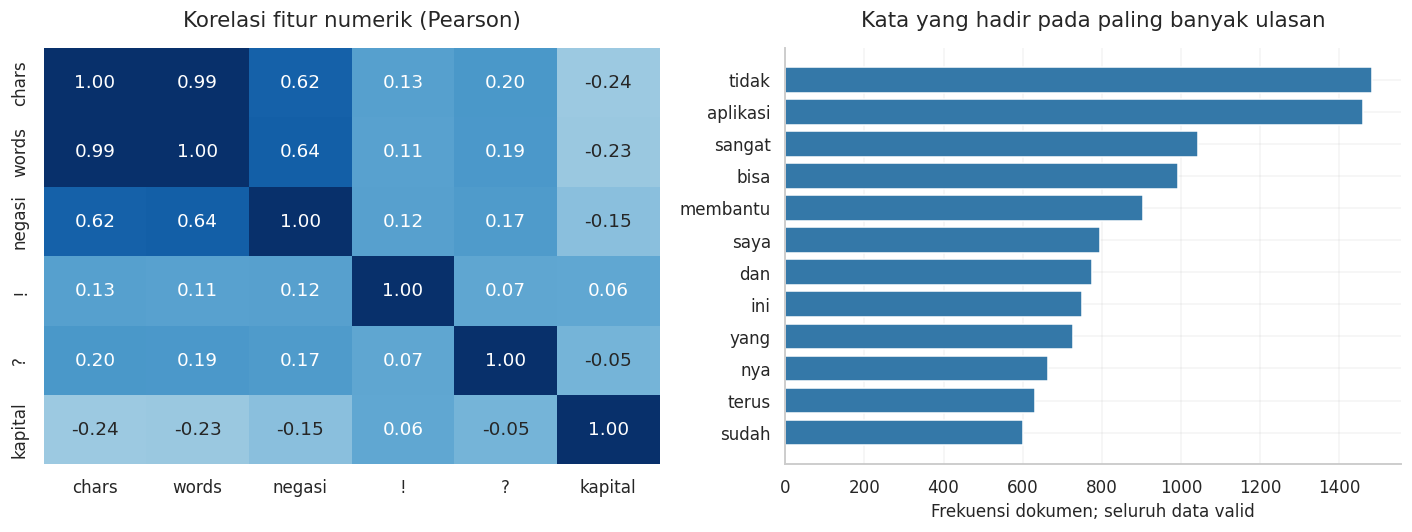

Fitur skala panjang dapat saling berkorelasi. Ablation nanti memeriksa apakah penambahannya membantu CV; grafik ini tidak digunakan untuk memilih fitur berdasarkan test holdout.

In [16]:
%%maintain_gov
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(features[NUMERIC_COLUMNS].corr().fillna(0), ax=axes[0], annot=True,
            fmt=".2f", cmap="Blues", vmin=-1, vmax=1, cbar=False,
            xticklabels=["chars","words","negasi","!","?","kapital"],
            yticklabels=["chars","words","negasi","!","?","kapital"])
axes[0].set_title("Korelasi fitur numerik (Pearson)")
vocabulary_counts = Counter()
for text in df.clean_text:
    vocabulary_counts.update(set(re.findall(r"\b[a-z]{3,}\b",text)))
blocked_terms = {"urltoken","emailtoken","numbertoken","reviewertoken"}
name_tokens = set(" ".join(df.get("userName",pd.Series(dtype=str)).astype(str)).casefold().split())
top_words = [(word,count) for word,count in vocabulary_counts.most_common()
             if word not in blocked_terms | name_tokens][:12]
assert len(top_words)>0,"Kosakata grafik kosong; periksa normalisasi dan pola token."
axes[1].barh([word for word,_ in top_words][::-1], [count for _,count in top_words][::-1], color="#3478A8")
axes[1].set(title="Kata yang hadir pada paling banyak ulasan", xlabel="Frekuensi dokumen; seluruh data valid")
axes[0].tick_params(axis="x",rotation=0)
save_show("04_feature_eda", fig)
note("Fitur skala panjang dapat saling berkorelasi. Ablation nanti memeriksa apakah penambahannya membantu CV; "
     "grafik ini tidak digunakan untuk memilih fitur berdasarkan test holdout.")

## 9. Sentiment analysis berbasis lexicon
Pencocokan **longest phrase first** menghindari penghitungan token yang sama
berulang. Negasi tiga token membalik tanda sampai tanda baca/konjungsi tertentu.
Aturan sederhana ini dapat gagal pada sarkasme atau struktur kalimat kompleks.
`undetermined` berarti tidak ada bukti kamus, bukan otomatis netral.
`mixed` berarti ada bukti polaritas positif dan negatif dalam satu ulasan.

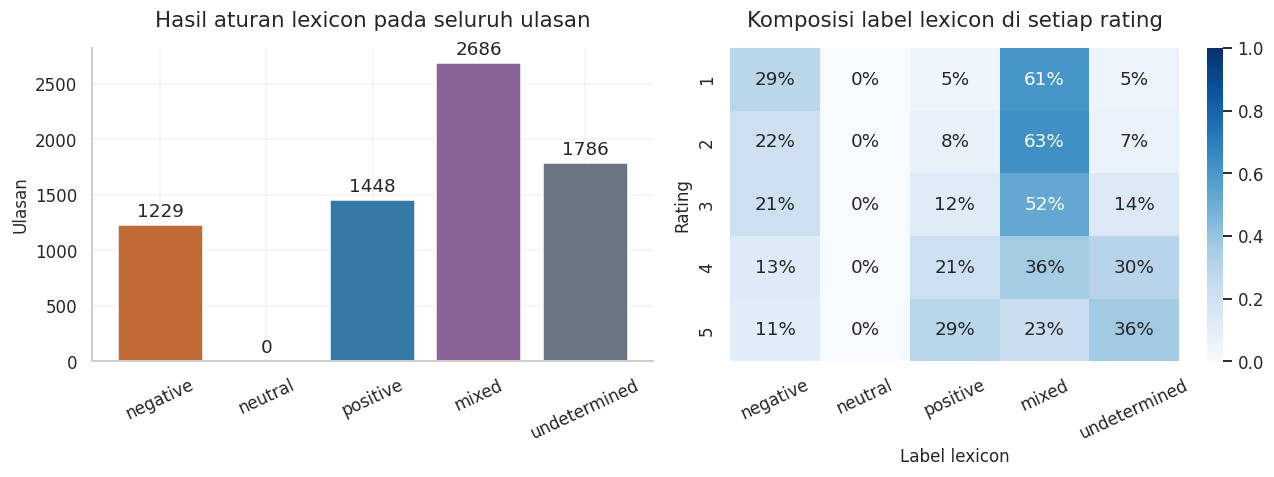

**Cakupan kamus:** 75.0% ulasan memiliki minimal satu kecocokan. Grafik rating × lexicon adalah perbandingan dua sinyal yang dapat berbeda, bukan matriks akurasi.

In [17]:
%%maintain_gov
LEX_BY_FIRST = defaultdict(list)
for term, weight in LEXICON.items():
    tokens = tuple(term.split())
    LEX_BY_FIRST[tokens[0]].append((tokens, weight))
for first in LEX_BY_FIRST:
    LEX_BY_FIRST[first].sort(key=lambda item: (-len(item[0]), item[0]))
def is_negated(tokens, index):
    previous = []
    for token in reversed(tokens[max(0,index-3):index]):
        if token in {".",",","!","?",";",":","tapi","tetapi","namun"}:
            break
        previous.append(token)
    return sum(token in NEGATORS for token in previous) % 2 == 1
def lexicon_sentiment(text):
    tokens, weights, index = text.split(), [], 0
    while index < len(tokens):
        matched = False
        for phrase, weight in LEX_BY_FIRST.get(tokens[index], []):
            if tuple(tokens[index:index+len(phrase)]) == phrase:
                weights.append(-weight if is_negated(tokens,index) else weight)
                index += len(phrase); matched = True; break
        if not matched:
            index += 1
    score = float(sum(weights)/np.sqrt(len(weights))) if weights else 0.0
    if not weights:
        label = "undetermined"
    elif any(value>0 for value in weights) and any(value<0 for value in weights):
        label = "mixed"
    else:
        label = "positive" if score>.3 else "negative" if score<-.3 else "neutral"
    return {"lexicon_score":score,"lexicon_label":label,"lexicon_hits":len(weights)}
lexicon_results = pd.DataFrame([lexicon_sentiment(text) for text in df.clean_text])
df = pd.concat([df, lexicon_results], axis=1)
lex_counts = df.lexicon_label.value_counts().reindex(COLORS, fill_value=0)
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
bars = axes[0].bar(lex_counts.index, lex_counts.values, color=[COLORS[label] for label in lex_counts.index])
axes[0].bar_label(bars, padding=3)
axes[0].set(title="Hasil aturan lexicon pada seluruh ulasan",ylabel="Ulasan")
axes[0].tick_params(axis="x",rotation=25)
cross = pd.crosstab(df.rating_value, df.lexicon_label).reindex(columns=COLORS, fill_value=0)
sns.heatmap(cross.div(cross.sum(axis=1),axis=0),annot=True,fmt=".0%",cmap="Blues",ax=axes[1],vmin=0,vmax=1)
axes[1].set(title="Komposisi label lexicon di setiap rating",xlabel="Label lexicon",ylabel="Rating")
axes[1].tick_params(axis="x",rotation=25)
save_show("05_lexicon_sentiment",fig)
note(f"**Cakupan kamus:** {(df.lexicon_hits>0).mean():.1%} ulasan memiliki minimal satu kecocokan. "
     "Grafik rating × lexicon adalah perbandingan dua sinyal yang dapat berbeda, bukan matriks akurasi.")

## 10. Siapkan anotasi manusia dan evaluasi independen
Template privat memuat 100 teks unik: 75 development dan 25 calon test manusia.
Untuk pelatihan human yang lebih stabil, tambah anotasi sehingga setiap kelas
punya cukup kelompok berbeda. Sampel diseimbangkan menurut rating untuk variasi;
hasilnya tidak mewakili prevalensi populasi. Rating tidak dicantumkan pada
template untuk mengurangi anchoring saat membaca teks.

Isi `sentiment` dengan negative/neutral/positive/mixed, `category` dengan taxonomy
yang disepakati, `severity` dan `issue_group` sesuai dampak. Dua annotator dapat
mengisi `annotator_a` dan `annotator_b`, lalu reviewer menetapkan `sentiment`
final. Isi `label_source=human`, `reviewer`, dan `approved=yes` hanya setelah
review nyata. Cohen's kappa nanti hanya dihitung bila dua kolom terisi.

Teks boleh mengandung identitas yang tidak tertangkap regex. Template dan label
per ulasan tidak masuk Git. Jangan mengganti kolom manusia dengan prediksi model.

### Pedoman pelabelan sebelum mode human

| Label | Pedoman awal untuk reviewer |
|---|---|
| `negative` | Teks menyatakan ketidakpuasan atau pengalaman buruk yang jelas |
| `positive` | Teks menyatakan kepuasan atau pengalaman baik yang jelas |
| `neutral` | Teks informatif tanpa evaluasi positif/negatif yang jelas |
| `mixed` | Ada evaluasi positif dan negatif yang bermakna dalam teks yang sama |

Ini pedoman awal untuk disepakati kelompok, bukan label otomatis. Sarkasme,
teks tanpa konteks dan permintaan fitur memerlukan pembacaan konteks; jangan
menggunakan rating sebagai jawaban saat menganotasi. Pisahkan label sentimen
dari kategori issue dan dampak severity. Catat perbedaan dua annotator, putuskan
melalui reviewer, lalu simpan alasan pada `notes`. Sampel 100 teks adalah titik
awal review, bukan jaminan ukuran sampel validasi mencukupi.

In [18]:
%%maintain_gov
annotation_pool = df.sort_values("reviewId").drop_duplicates("text_group")
parts = []
for rating in range(1,6):
    candidates = annotation_pool.loc[annotation_pool.rating_value.eq(rating)]
    parts.append(candidates.sample(min(20,len(candidates)),random_state=SEED))
annotation_selection = pd.concat(parts).sample(frac=1,random_state=SEED).reset_index(drop=True)
annotation_template = pd.DataFrame({"reviewId":annotation_selection.reviewId,
    "text":annotation_selection.safe_source_text.map(lambda text: normalize_text(text,{})),
    "suggested_partition":["development" if i%4 else "test" for i in range(len(annotation_selection))]})
for column in ("annotator_a","annotator_b","sentiment","category","severity","issue_group","label_source","reviewer","approved","notes"):
    annotation_template[column] = ""
template_path = PRIVATE / "annotation_template.csv"
if not template_path.exists():
    annotation_template.to_csv(template_path,index=False,encoding="utf-8-sig")
print("Template tersedia:",len(annotation_template),"teks unik; kolom label tetap kosong.")
print("Lokasi runtime:", str(template_path.relative_to(OUTPUT)))

Template tersedia: 100 teks unik; kolom label tetap kosong.
Lokasi runtime: private_artifacts\annotation_template.csv


### 10.1 Input anotasi untuk mode human
Mode proksi tidak memerlukan file anotasi. Untuk mode human, ubah
`LABEL_MODE="human"` sebelum Run all dan masukkan `annotations.csv` yang
sudah direview ke dalam ZIP dataset. Path anotasi lokal dapat diberikan
melalui `ANNOTATION_PATH` saat menjalankan di luar Colab.

Kolom `suggested_partition` dihormati agar test yang telah disisihkan tidak
dipakai untuk tuning. Jangan mengubah partisi berdasarkan kesalahan model.
Anotasi tanpa kolom partisi menggunakan grouped holdout baru.


In [19]:
%%maintain_gov
annotations = None
annotation_bytes = None
if LABEL_MODE == "human":
    if ANNOTATION_PATH:
        annotation_bytes = Path(ANNOTATION_PATH).read_bytes()
    elif "annotations.csv" in members:
        annotation_bytes = members["annotations.csv"]
    else:
        try:
            from google.colab import files
            user_labels = files.upload()
            csv_names = [name for name in user_labels if name.lower().endswith(".csv")]
            if len(csv_names) != 1:
                raise ValueError("Unggah tepat satu CSV anotasi.")
            annotation_bytes = user_labels[csv_names[0]]
        except ImportError as exc:
            raise RuntimeError("Isi MAINTAINGOV_ANNOTATIONS saat menjalankan di luar Colab.") from exc
    annotations = pd.read_csv(io.BytesIO(annotation_bytes),dtype=str).fillna("")
    must = {"reviewId","sentiment","label_source","reviewer","approved"}
    if not must <= set(annotations):
        raise ValueError(f"Kolom anotasi belum lengkap: {must-set(annotations)}")
    for column in must:
        annotations[column] = annotations[column].str.strip()
    if annotations.reviewId.duplicated().any():
        raise ValueError("Satu reviewId hanya boleh punya satu label final; konsolidasikan reviewer.")
    if not set(annotations.reviewId) <= set(df.reviewId):
        raise ValueError("Anotasi berisi ID yang tidak ada pada data valid.")
    accepted = (annotations.label_source.eq("human") & annotations.approved.str.casefold().eq("yes") & annotations.reviewer.ne(""))
    allowed = {"negative","neutral","positive","mixed"}
    if not annotations.loc[accepted,"sentiment"].isin(allowed).all():
        raise ValueError("Label sentiment manusia di luar vocabulary yang disepakati.")
    annotations = annotations.loc[accepted].copy()
    print("Label manusia yang lolos penanda review:",len(annotations))
    if {"annotator_a","annotator_b"} <= set(annotations):
        paired = annotations.loc[annotations.annotator_a.isin(allowed) & annotations.annotator_b.isin(allowed)]
        if len(paired)>=10 and (paired.annotator_a.nunique()>1 or paired.annotator_b.nunique()>1):
            print("Cohen kappa (agreement, bukan akurasi):",round(cohen_kappa_score(paired.annotator_a,paired.annotator_b),3),"n=",len(paired))
else:
    print("Mode rating_proxy: tidak ada label manusia yang diasumsikan tersedia.")

Mode rating_proxy: tidak ada label manusia yang diasumsikan tersedia.


## 11. Tetapkan target dan kolom yang boleh masuk model
Mode proksi memetakan rating 1–2 → negative, 3 → neutral, 4–5 → positive.
Pemetaan dicatat, bukan dianggap label sentimen yang benar. Perbedaan rating
dalam kelompok teks sama menunjukkan noise target dan akan dilaporkan.
Model hanya melihat teks dan fitur bentuk teks, sehingga rating tidak bocor
langsung menjadi prediktor bagi target yang dibentuk dari rating.

In [20]:
%%maintain_gov
if LABEL_MODE == "rating_proxy":
    model_data = df.copy()
    model_data["target"] = model_data.rating_value.map({1:"negative",2:"negative",3:"neutral",4:"positive",5:"positive"})
    TARGET_DESCRIPTION = "label proksi rating; belum gold sentiment"
elif LABEL_MODE == "human":
    if annotations is None or len(annotations)<30:
        raise ValueError("Mode human memerlukan minimal 30 anotasi reviewed; ini batas teknis awal, bukan jaminan kecukupan statistik.")
    label_columns = ["reviewId","sentiment"] + (["suggested_partition"] if "suggested_partition" in annotations else [])
    model_data = df.merge(annotations[label_columns],on="reviewId",validate="one_to_one")
    model_data["target"] = model_data.sentiment
    TARGET_DESCRIPTION = "sentimen berlabel manusia sesuai file review"
else:
    raise ValueError("LABEL_MODE harus rating_proxy atau human.")
model_data = model_data.reset_index(drop=True)
X = feature_frame(model_data.safe_source_text, SLANG)
y = model_data.target.to_numpy()
groups = model_data.text_group.to_numpy()
LABELS = sorted(np.unique(y))
if len(LABELS)<2:
    raise ValueError("Pelatihan memerlukan minimal dua kelas.")
group_conflicts = model_data.groupby("text_group").target.nunique()
print("Target:",TARGET_DESCRIPTION)
print("Kelompok teks dengan beberapa label:",int((group_conflicts>1).sum()))
display(model_data.target.value_counts().reindex(LABELS).rename("ulasan").to_frame())
assert set(X.columns)=={"clean_text",*NUMERIC_COLUMNS}
assert not {"rating","rating_value","userName","reviewId","target","lexicon_score"} & set(X.columns)

Target: label proksi rating; belum gold sentiment
Kelompok teks dengan beberapa label: 28


,ulasan
target,
negative,2199
neutral,486
positive,4464


## 12. Holdout berbasis kelompok — dikunci sebelum pelatihan
`StratifiedGroupKFold` mengusahakan proporsi kelas sambil menjaga satu kelompok
teks tetap utuh. Kelompok ditentukan setelah preprocessing, sehingga hasil
normalisasi identik tidak berada di train dan test. Ini belum menghilangkan
kemiripan semantik atau ketergantungan dari pengguna yang sama.

Kelas langka dan grup besar dapat membuat proporsi tidak tepat 80/20. Notebook
memeriksa kelas dan overlap secara eksplisit. Data test hanya untuk penilaian
akhir. Sel EDA sebelumnya dipakai untuk audit dan asumsi tetap, bukan fitting
TF-IDF atau seleksi fitur menggunakan label test.

Split ini menilai kelompok teks lain dalam snapshot historis, bukan performa pada masa depan. Untuk klaim deployment periode mendatang, lakukan evaluasi temporal terpisah dengan periode terakhir yang dikunci lebih dahulu dan keluarkan kelompok teks yang melintasi batas waktu. Jangan memilih cutoff atau model berdasarkan skor periode test tersebut.

,train,test
negative,1786,413
neutral,379,107
positive,3352,1112


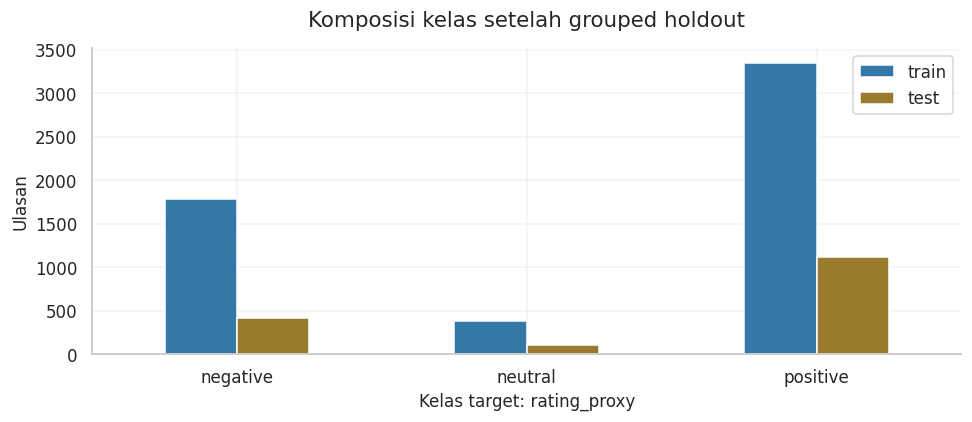

Train 5,517; test 1,632 (22.8%); overlap grup = 0.


In [21]:
%%maintain_gov
manual_partition = (LABEL_MODE=="human" and "suggested_partition" in model_data)
if manual_partition:
    partition = model_data.suggested_partition.str.strip().str.casefold()
    if not partition.isin(["development","test"]).all():
        raise ValueError("Isi suggested_partition development/test untuk semua anotasi reviewed.")
    train_index = np.flatnonzero(partition.eq("development"))
    test_index = np.flatnonzero(partition.eq("test"))
else:
    per_class_groups = model_data.groupby("target").text_group.nunique()
    split_folds = min(HOLDOUT_FOLDS,int(per_class_groups.min()))
    if split_folds<2:
        raise ValueError("Tambah anotasi kelompok berbeda: tiap kelas perlu >=2 kelompok untuk holdout.")
    holdout = StratifiedGroupKFold(n_splits=split_folds,shuffle=True,random_state=SEED)
    train_index,test_index = next(holdout.split(X,y,groups))
assert len(train_index) and len(test_index)
assert not set(groups[train_index]) & set(groups[test_index]), "Teks kelompok menyeberangi split!"
if set(y[train_index]) != set(LABELS) or set(y[test_index]) != set(LABELS):
    raise ValueError("Satu kelas tidak terwakili pada train/test. Tambah label/grup; jangan memakai test untuk tuning.")
X_train,X_test = X.iloc[train_index].copy(),X.iloc[test_index].copy()
y_train,y_test = y[train_index],y[test_index]
groups_train,groups_test = groups[train_index],groups[test_index]
split_table = pd.DataFrame({"train":pd.Series(y_train).value_counts(),"test":pd.Series(y_test).value_counts()}).reindex(LABELS).fillna(0).astype(int)
display(split_table)
ax = split_table.plot.bar(figsize=(9,4),color=["#3478A8","#9A7B2E"],rot=0)
ax.set(title="Komposisi kelas setelah grouped holdout",xlabel=f"Kelas target: {LABEL_MODE}",ylabel="Ulasan")
save_show("06_grouped_split",ax.figure)
split_manifest = model_data[["reviewId","text_group","target"]].copy()
split_manifest["partition"] = "test"
split_manifest.loc[train_index,"partition"] = "train"
split_manifest.to_csv(PRIVATE / "split_manifest.csv",index=False)
print(f"Train {len(train_index):,}; test {len(test_index):,} ({len(test_index)/len(model_data):.1%}); overlap grup = 0.")

## 13. Fold CV untuk seluruh eksperimen model
Fold yang sama dipakai baseline, model pembanding, tuning, ablation dan learning
curve. Jumlah fold otomatis dibatasi kelompok per kelas. Setiap fold harus
memiliki semua kelas pada train dan validation; tidak ada vocabulary atau
chi-square yang difit sebelum CV. Macro-F1 menjadi metrik pemilihan utama.

In [22]:
%%maintain_gov
training_meta = model_data.iloc[train_index]
group_counts = training_meta.groupby("target").text_group.nunique()
n_folds = min(CV_FOLDS,int(group_counts.min()))
if n_folds<2:
    raise ValueError("Kelompok per kelas terlalu sedikit untuk CV; tambah label manusia.")
cv_splitter = StratifiedGroupKFold(n_splits=n_folds,shuffle=True,random_state=SEED+1)
CV = list(cv_splitter.split(X_train,y_train,groups_train))
fold_details = []
for fold,(left,right) in enumerate(CV,1):
    assert not set(groups_train[left]) & set(groups_train[right])
    if set(y_train[left])!=set(LABELS) or set(y_train[right])!=set(LABELS):
        raise ValueError("Kelas tidak lengkap dalam fold CV; tambah data atau kurangi CV_FOLDS.")
    fold_details.append({"fold":fold,"train_rows":len(left),"validation_rows":len(right),
                         "train_groups":len(set(groups_train[left])),"validation_groups":len(set(groups_train[right])),"group_overlap":0})
display(pd.DataFrame(fold_details))
SCORING = {"macro_f1":"f1_macro","balanced_accuracy":"balanced_accuracy","accuracy":"accuracy"}

,fold,train_rows,validation_rows,train_groups,validation_groups,group_overlap
0,1,3846,1671,2858,1398,0
1,2,3802,1715,2830,1426,0
2,3,3386,2131,2824,1432,0


## 14. Pipeline fitur: TF-IDF kata + karakter + statistik teks
TF-IDF kata menangkap unigram/bigram, karakter membantu variasi ejaan.
`SelectPercentile(chi2)` melakukan pemilihan fitur nonnegatif **di dalam pipeline**
pada setiap fold. Fitur numerik diskalakan di dalam fold, tanpa centering agar
tetap kompatibel dengan Naive Bayes. Vocabulary dibatasi untuk RAM Colab.

Seleksi pada TF-IDF menggunakan chi-square sebagai ranking praktis fitur
nonnegatif; p-value-nya tidak ditafsirkan sebagai uji hipotesis formal atas count
mentah. Persentase seleksi dipilih melalui CV, bukan berdasarkan hasil test.

### Bagaimana seleksi fitur tetap terpisah dari validation
Untuk setiap fold: **fit TF-IDF di fold train → pilih fitur chi-square di fold
train → fit scaler di fold train → fit classifier → transform dan nilai fold
validation**. Setelah parameter dipilih, pipeline difit ulang pada seluruh train;
test hanya ditransform dengan pipeline tersebut. Menyeleksi fitur sekali pada
seluruh data sebelum CV akan membocorkan informasi label validation.

`min_df` menyaring istilah terlalu jarang; `max_features` membatasi dimensi/RAM;
`percentile` menentukan bagian fitur yang dipertahankan; `C` mengatur kekuatan
regularisasi terbalik pada model linear; `alpha` memberi smoothing pada NB;
`class_weight` mencoba penyeimbangan penalti kelas. Nilai terbaik ditentukan CV,
bukan dipilih karena terlihat bagus pada test. SMOTE tidak digunakan pada alur
teks sparse ini; data sintetis tidak dibuat sebelum split.

In [23]:
%%maintain_gov
def make_features(percentile=50, with_char=True, with_numeric=True):
    word = Pipeline([("tfidf",TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.99,
        max_features=16000,sublinear_tf=True,token_pattern=r"(?u)\b\w+\b")),
        ("select",SelectPercentile(chi2,percentile=percentile))])
    transformers = [("word",word,"clean_text")]
    if with_char:
        char = Pipeline([("tfidf",TfidfVectorizer(analyzer="char_wb",ngram_range=(3,5),
            min_df=2,max_features=10000,sublinear_tf=True)),
            ("select",SelectPercentile(chi2,percentile=percentile))])
        transformers.append(("char",char,"clean_text"))
    if with_numeric:
        transformers.append(("numeric",StandardScaler(with_mean=False),NUMERIC_COLUMNS))
    return ColumnTransformer(transformers,sparse_threshold=1.0,remainder="drop")
def make_model(classifier,**feature_options):
    return Pipeline([("features",make_features(**feature_options)),("classifier",classifier)])
classifiers = {
    "Dummy_majority":DummyClassifier(strategy="most_frequent"),
    "MultinomialNB":MultinomialNB(alpha=1.0),
    "LogisticRegression":LogisticRegression(C=1.0,class_weight="balanced",solver="liblinear",max_iter=1000,random_state=SEED),
    "LinearSVC":LinearSVC(C=1.0,class_weight="balanced",dual=False,max_iter=10000,random_state=SEED),
}
def cv_summary(estimator,name):
    scores = cross_validate(estimator,X_train,y_train,cv=CV,scoring=SCORING,
                            n_jobs=N_JOBS,error_score="raise",return_train_score=True)
    return {"experiment":name,"cv_macro_f1":float(scores["test_macro_f1"].mean()),
        "cv_sd":float(scores["test_macro_f1"].std(ddof=1)),
        "train_macro_f1":float(scores["train_macro_f1"].mean()),
        "cv_balanced_accuracy":float(scores["test_balanced_accuracy"].mean()),
        "cv_accuracy":float(scores["test_accuracy"].mean()),"fit_seconds":float(scores["fit_time"].mean())}

## 15. Bandingkan baseline dan tiga keluarga model
Dummy menunjukkan hasil bila semua ulasan diprediksi sebagai kelas mayoritas.
Bandingkan macro-F1 untuk menghindari kesimpulan dari accuracy yang tinggi pada
data timpang. SD antarfold adalah variasi antarpartisi, **bukan confidence interval**.

CV berjalan: Dummy_majority


CV berjalan: MultinomialNB


CV berjalan: LogisticRegression


CV berjalan: LinearSVC


,experiment,cv_macro_f1,cv_sd,train_macro_f1,cv_balanced_accuracy,cv_accuracy,fit_seconds
2,LogisticRegression,0.6165,0.0158,0.8424,0.6179,0.8145,4.8606
3,LinearSVC,0.6029,0.0158,0.9474,0.6037,0.8056,3.4870
1,MultinomialNB,0.5640,0.0142,0.6010,0.5927,0.8147,1.3789
0,Dummy_majority,0.2507,0.0113,0.2516,0.3333,0.6035,0.0043


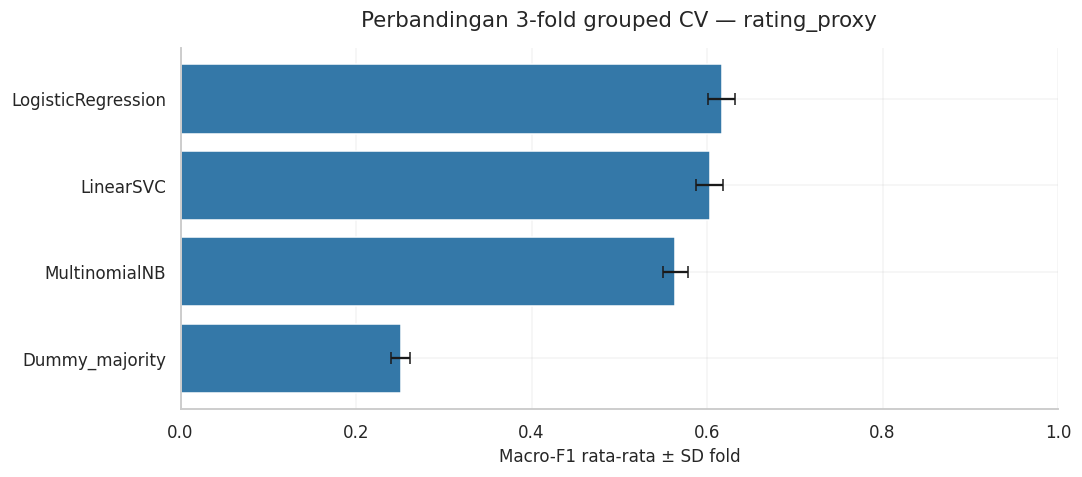

Keluarga model untuk tuning: LogisticRegression


In [24]:
%%maintain_gov
comparison_rows = []
for name,classifier in classifiers.items():
    print("CV berjalan:",name,flush=True)
    estimator = classifier if name.startswith("Dummy") else make_model(clone(classifier))
    comparison_rows.append(cv_summary(estimator,name))
comparison = pd.DataFrame(comparison_rows).sort_values("cv_macro_f1",ascending=False)
display(comparison.round(4))
fig,ax = plt.subplots(figsize=(10,4.5))
ordered = comparison.sort_values("cv_macro_f1")
ax.barh(ordered.experiment,ordered.cv_macro_f1,xerr=ordered.cv_sd,color="#3478A8",capsize=4)
ax.set(title=f"Perbandingan {n_folds}-fold grouped CV — {LABEL_MODE}",xlabel="Macro-F1 rata-rata ± SD fold",xlim=(0,1))
save_show("07_model_comparison",fig)
eligible = comparison.loc[~comparison.experiment.str.startswith("Dummy")]
winner_name = eligible.iloc[0].experiment
print("Keluarga model untuk tuning:",winner_name)

## 16. Hyperparameter tuning pada train saja
Randomized search mengeksplorasi `C/alpha`, bobot kelas, vocabulary minimum dan
persentase fitur. Keluarga model dipilih dari CV sebelumnya. Pemakaian CV yang
sama untuk pemilihan dan tuning membuat best CV optimistis; **holdout yang belum
disentuh menjadi evaluasi utama**, bukan menganggap best CV sebagai test score.
Nested CV dapat ditambahkan saat label manusia cukup dan anggaran komputasi lebih
besar; tidak wajib untuk alur grouped CV + untouched holdout ini.

,rank_test_score,mean_test_score,std_test_score,mean_train_score,mean_fit_time,params
11,1,0.622617,0.015606,0.836497,2.821202,"{'features__word__tfidf__min_df': 3, 'features__word__select_..."
6,2,0.616885,0.014804,0.849525,2.715053,"{'features__word__tfidf__min_df': 2, 'features__word__select_..."
3,3,0.616286,0.014143,0.839986,4.089959,"{'features__word__tfidf__min_df': 2, 'features__word__select_..."
7,4,0.612532,0.012878,0.918744,2.792667,"{'features__word__tfidf__min_df': 1, 'features__word__select_..."
9,5,0.610535,0.008994,0.929504,2.894762,"{'features__word__tfidf__min_df': 2, 'features__word__select_..."
5,6,0.609781,0.012091,0.800880,4.018828,"{'features__word__tfidf__min_df': 2, 'features__word__select_..."
8,7,0.609296,0.012666,0.737632,2.769160,"{'features__word__tfidf__min_df': 3, 'features__word__select_..."
0,8,0.603922,0.010957,0.736086,1.707151,"{'features__word__tfidf__min_df': 2, 'features__word__select_..."


Parameter terbaik: {'features__word__tfidf__min_df': 3, 'features__word__select__percentile': 50, 'features__char__select__percentile': 100, 'classifier__class_weight': 'balanced', 'classifier__C': 1.0}
Best CV macro-F1 0.6226; tuning 266.0 detik. Test belum dipakai.


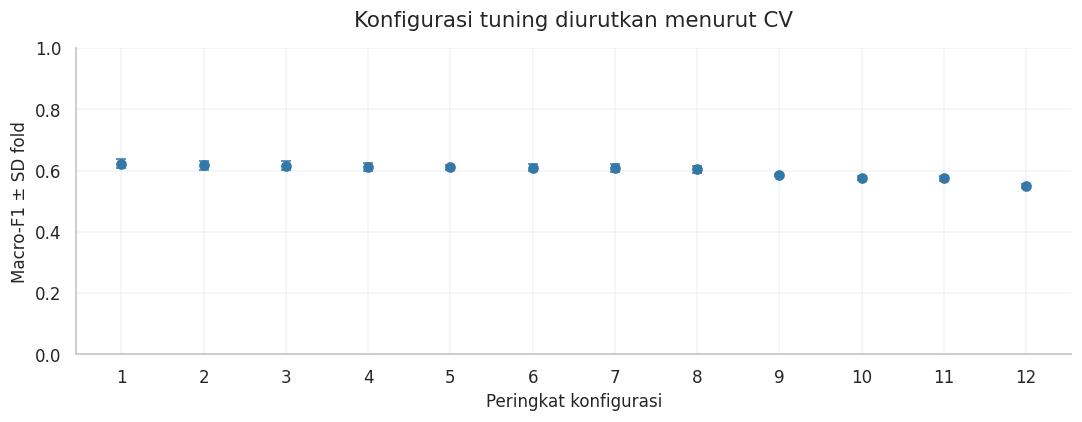

In [25]:
%%maintain_gov
search_estimator = make_model(clone(classifiers[winner_name]))
parameter_space = {
    "features__word__select__percentile":[25,50,75,100],
    "features__char__select__percentile":[25,50,75,100],
    "features__word__tfidf__min_df":[1,2,3],
}
if winner_name=="MultinomialNB":
    parameter_space["classifier__alpha"] = [.1,.5,1.0,2.0]
else:
    parameter_space["classifier__C"] = [.25,.5,1.0,2.0,4.0]
    parameter_space["classifier__class_weight"] = [None,"balanced"]
search = RandomizedSearchCV(search_estimator,parameter_space,n_iter=SEARCH_ITER,
    scoring="f1_macro",cv=CV,refit=True,n_jobs=N_JOBS,random_state=SEED,
    return_train_score=True,error_score="raise",verbose=0)
started = time.perf_counter()
search.fit(X_train,y_train)
tuning_seconds = time.perf_counter()-started
tuning = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(tuning[["rank_test_score","mean_test_score","std_test_score","mean_train_score","mean_fit_time","params"]].head(8))
print("Parameter terbaik:",search.best_params_)
print(f"Best CV macro-F1 {search.best_score_:.4f}; tuning {tuning_seconds:.1f} detik. Test belum dipakai.")
fig,ax = plt.subplots(figsize=(10,4))
plot_tuning = tuning.head(min(12,len(tuning))).reset_index(drop=True)
ax.errorbar(np.arange(1,len(plot_tuning)+1),plot_tuning.mean_test_score,
            yerr=plot_tuning.std_test_score,fmt="o",color="#3478A8",capsize=3)
ax.set(title="Konfigurasi tuning diurutkan menurut CV",xlabel="Peringkat konfigurasi",ylabel="Macro-F1 ± SD fold",ylim=(0,1))
ax.set_xticks(np.arange(1,len(plot_tuning)+1))
save_show("08_tuning",fig)

## 17. Ablation — apakah karakter, statistik teks, dan seleksi membantu?
Sel ini membandingkan pilihan fitur menggunakan train/CV saja. Hyperparameter
classifier mengikuti hasil tuning. Kandidat final dipilih dari skor CV tertinggi
antara tuned, word-only, dan semua fitur tanpa seleksi; tie memakai model tuned.
CV ablation bukan pengujian statistik bahwa selisih kecil pasti signifikan.

Pembanding Word_only dan All_without_selection memakai setelan default pipeline fitur dengan classifier hasil tuning. Karena min_df dapat berbeda dari model tuned, selisih CV adalah perbandingan konfigurasi; bukan estimasi efek murni satu kelompok fitur.

,experiment,cv_macro_f1,cv_sd,train_macro_f1,cv_balanced_accuracy,cv_accuracy,fit_seconds
0,Tuned,0.6226,0.0191,0.8365,0.6233,0.8151,3.3922
2,All_without_selection,0.6178,0.0147,0.8715,0.6189,0.8140,3.1002
1,Word_only,0.6081,0.0160,0.8217,0.6122,0.8145,0.4842


Model final sebelum membuka test: LogisticRegression / Tuned


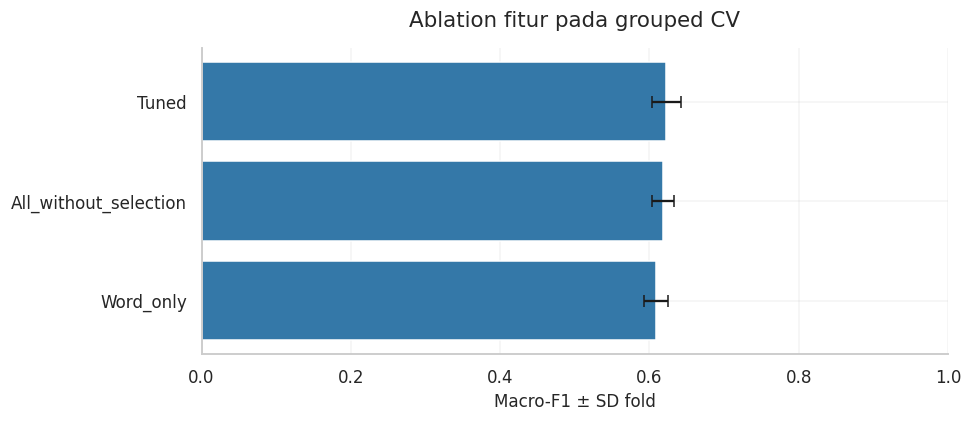

In [26]:
%%maintain_gov
ablation_estimators = {
    "Tuned":clone(search.best_estimator_),
    "Word_only":make_model(clone(search.best_estimator_.named_steps["classifier"]),with_char=False,with_numeric=False),
    "All_without_selection":make_model(clone(search.best_estimator_.named_steps["classifier"]),percentile=100),
}
ablation_rows = [cv_summary(estimator,name) for name,estimator in ablation_estimators.items()]
ablation = pd.DataFrame(ablation_rows).sort_values("cv_macro_f1",ascending=False,kind="stable")
display(ablation.round(4))
final_experiment = ablation.iloc[0].experiment
final_model = clone(ablation_estimators[final_experiment]).fit(X_train,y_train)
print("Model final sebelum membuka test:",winner_name,"/",final_experiment)
fig,ax = plt.subplots(figsize=(9,4))
ax.barh(ablation.experiment[::-1],ablation.cv_macro_f1[::-1],xerr=ablation.cv_sd[::-1],color="#3478A8",capsize=4)
ax.set(title="Ablation fitur pada grouped CV",xlabel="Macro-F1 ± SD fold",xlim=(0,1))
save_show("09_ablation",fig)

## 18. Interpretasi fitur yang dipilih
Jumlah fitur sebelum/sesudah seleksi membantu memeriksa efek chi-square.
Koefisien linear atau log-probability NB menunjukkan asosiasi model, bukan
penyebab keluhan. Grafik tidak mengganti pemeriksaan manusia terhadap kesalahan.
Nama fitur lengkap diekspor secara privat karena vocabulary dapat membawa istilah
dari teks sumber. Grafik merangkum tipe fitur tanpa menampilkan identitas.

,type,before,after
0,word,4428,2214
1,char,10000,10000
2,numeric,6,6


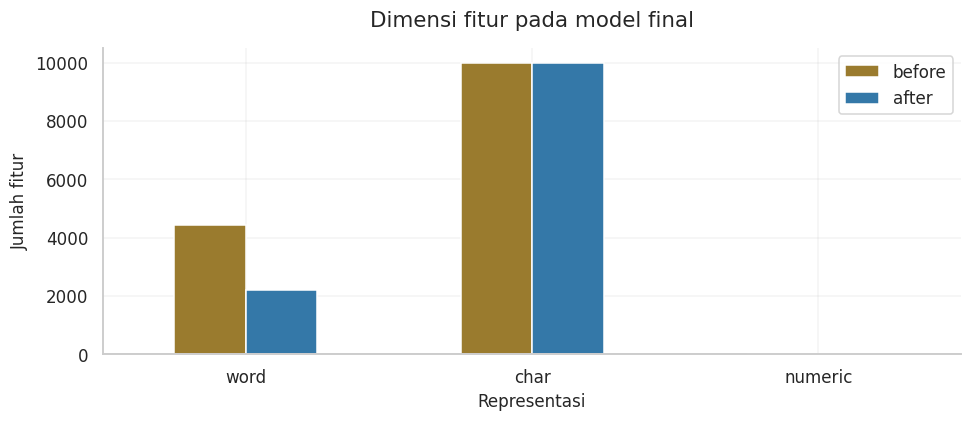

In [27]:
%%maintain_gov
fitted_features = final_model.named_steps["features"]
feature_names = fitted_features.get_feature_names_out()
selection_rows = []
for name,transformer,columns in fitted_features.transformers_:
    if name in {"word","char"}:
        selection_rows.append({"type":name,"before":len(transformer.named_steps["tfidf"].vocabulary_),
                               "after":int(transformer.named_steps["select"].get_support().sum())})
    elif name=="numeric":
        selection_rows.append({"type":name,"before":len(NUMERIC_COLUMNS),"after":len(NUMERIC_COLUMNS)})
selection = pd.DataFrame(selection_rows)
display(selection)
ax = selection.set_index("type")[["before","after"]].plot.bar(figsize=(9,4),rot=0,color=["#9A7B2E","#3478A8"])
ax.set(title="Dimensi fitur pada model final",xlabel="Representasi",ylabel="Jumlah fitur")
save_show("10_feature_selection",ax.figure)
classifier = final_model.named_steps["classifier"]
coefficients = classifier.coef_ if hasattr(classifier,"coef_") else classifier.feature_log_prob_
importance = np.abs(coefficients).mean(axis=0)
pd.DataFrame({"feature":feature_names,"mean_abs_weight":importance}).sort_values("mean_abs_weight",ascending=False).to_csv(PRIVATE/"feature_weights.csv",index=False)
assert len(feature_names)==len(importance)

## 19. Learning curve pada data train
Train bertambah di dalam setiap fold; validation fold tetap terpisah grup.
Garis menunjukkan apakah tambahan data cenderung membantu dan apakah ada gap
train–validation. Area ±SD antarfold bukan CI. Pada anotasi kecil, bagian ini
dilewati sampai cukup data agar subset tidak kehilangan kelas.

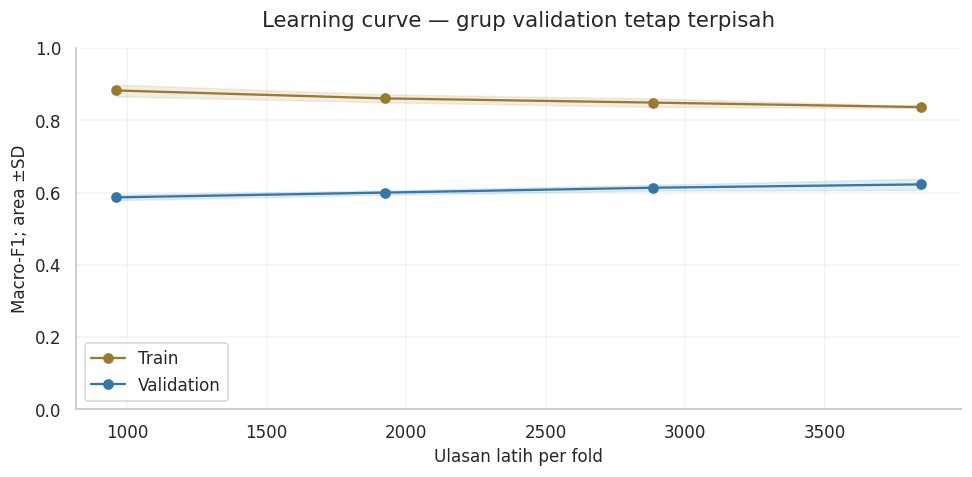

In [28]:
%%maintain_gov
learning_result = None
if RUN_LEARNING_CURVE and min(len(left) for left,_ in CV)>=100:
    sizes,train_scores,valid_scores = learning_curve(clone(final_model),X_train,y_train,
        cv=CV,train_sizes=[.25,.5,.75,1.0],scoring="f1_macro",n_jobs=N_JOBS,
        shuffle=True,random_state=SEED,error_score=np.nan)
    learning_result = {"sizes":sizes.tolist(),"train_mean":np.nanmean(train_scores,axis=1).tolist(),
                       "validation_mean":np.nanmean(valid_scores,axis=1).tolist()}
    fig,ax = plt.subplots(figsize=(9,4.5))
    for scores,label,color in [(train_scores,"Train","#9A7B2E"),(valid_scores,"Validation","#3478A8")]:
        mean,std = np.nanmean(scores,axis=1),np.nanstd(scores,axis=1)
        ax.plot(sizes,mean,"o-",label=label,color=color)
        ax.fill_between(sizes,np.clip(mean-std,0,1),np.clip(mean+std,0,1),color=color,alpha=.12)
    ax.set(title="Learning curve — grup validation tetap terpisah",xlabel="Ulasan latih per fold",ylabel="Macro-F1; area ±SD",ylim=(0,1))
    ax.legend(); save_show("11_learning_curve",fig)
else:
    print("Learning curve dilewati: dinonaktifkan atau data train/fold belum cukup.")

## 20. Test holdout — evaluasi akhir setelah model dikunci
Hanya model yang telah dipilih di atas dan dummy baseline yang dinilai pada
test. Laporan menampilkan precision/recall/F1 per kelas, macro average, balanced
accuracy, dan jumlah ulasan. Matriks kiri jumlah ulasan; kanan proporsi per
kelas sebenarnya. Tingginya skor proksi tidak mengubah statusnya menjadi gold.

### Cara membaca metrik

| Metrik | Pertanyaan yang dijawab |
|---|---|
| Accuracy | Berapa proporsi seluruh prediksi yang sama dengan target? Dapat didominasi kelas terbesar. |
| Precision per kelas | Dari prediksi kelas tersebut, berapa yang sesuai target? |
| Recall per kelas | Dari target kelas tersebut, berapa yang berhasil ditemukan? |
| F1 per kelas | Rata-rata harmonik precision dan recall kelas tersebut. |
| Macro-F1 | Rata-rata F1 dengan bobot sama untuk setiap kelas; dipakai memilih model. |
| Balanced accuracy | Rata-rata recall antarkelas; menyoroti kelas yang sulit ditemukan. |
| Support | Jumlah ulasan target kelas tersebut; nilai kecil membuat hasil lebih tidak stabil. |
| AP | Ringkasan kurva precision–recall dari skor ranking one-vs-rest. |

Semua makna tersebut mengacu pada **target run ini**. Pada `rating_proxy`,
kesesuaian prediksi dengan target adalah kesesuaian terhadap pemetaan bintang.
Nilai tinggi belum membuktikan model memahami sentimen manusia.

,final_model,dummy_majority
accuracy,0.8438,0.6814
balanced_accuracy,0.6282,0.3333
macro_f1,0.6229,0.2702


,precision,recall,f1-score,support
negative,0.735,0.840,0.784,413
neutral,0.222,0.131,0.165,107
positive,0.926,0.914,0.920,1112
macro avg,0.628,0.628,0.623,1632
weighted avg,0.832,0.844,0.836,1632


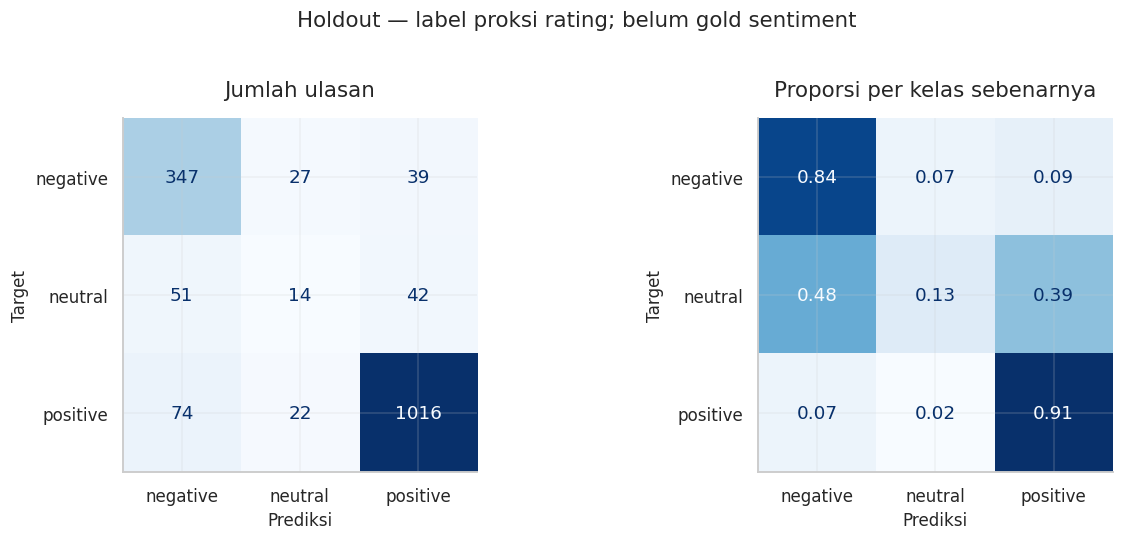

**Hasil run ini:** macro-F1 0.623, balanced accuracy 0.628, n=1,632. Target: **label proksi rating; belum gold sentiment**.

In [29]:
%%maintain_gov
y_pred = final_model.predict(X_test)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train,y_train)
dummy_pred = dummy.predict(X_test)
def metrics_dict(truth,prediction):
    return {"accuracy":float(accuracy_score(truth,prediction)),
            "balanced_accuracy":float(balanced_accuracy_score(truth,prediction)),
            "macro_f1":float(f1_score(truth,prediction,labels=LABELS,average="macro",zero_division=0))}
test_metrics = metrics_dict(y_test,y_pred)
dummy_metrics = metrics_dict(y_test,dummy_pred)
display(pd.DataFrame({"final_model":test_metrics,"dummy_majority":dummy_metrics}).round(4))
report = classification_report(y_test,y_pred,labels=LABELS,output_dict=True,zero_division=0)
per_class_report = pd.DataFrame({key:value for key,value in report.items() if isinstance(value,dict)}).T
per_class_report["support"] = per_class_report["support"].astype(int)
display(per_class_report.round(3))
fig,axes = plt.subplots(1,2,figsize=(12,4.8))
for ax,normalization,title in [(axes[0],None,"Jumlah ulasan"),(axes[1],"true","Proporsi per kelas sebenarnya")]:
    ConfusionMatrixDisplay.from_predictions(y_test,y_pred,labels=LABELS,normalize=normalization,
        display_labels=LABELS,cmap="Blues",ax=ax,colorbar=False,values_format="d" if normalization is None else ".2f")
    ax.set(title=title,xlabel="Prediksi",ylabel="Target")
fig.suptitle(f"Holdout — {TARGET_DESCRIPTION}",y=1.02,fontsize=14)
save_show("12_test_confusion",fig)
note(f"**Hasil run ini:** macro-F1 {test_metrics['macro_f1']:.3f}, balanced accuracy "
     f"{test_metrics['balanced_accuracy']:.3f}, n={len(y_test):,}. Target: **{TARGET_DESCRIPTION}**.")

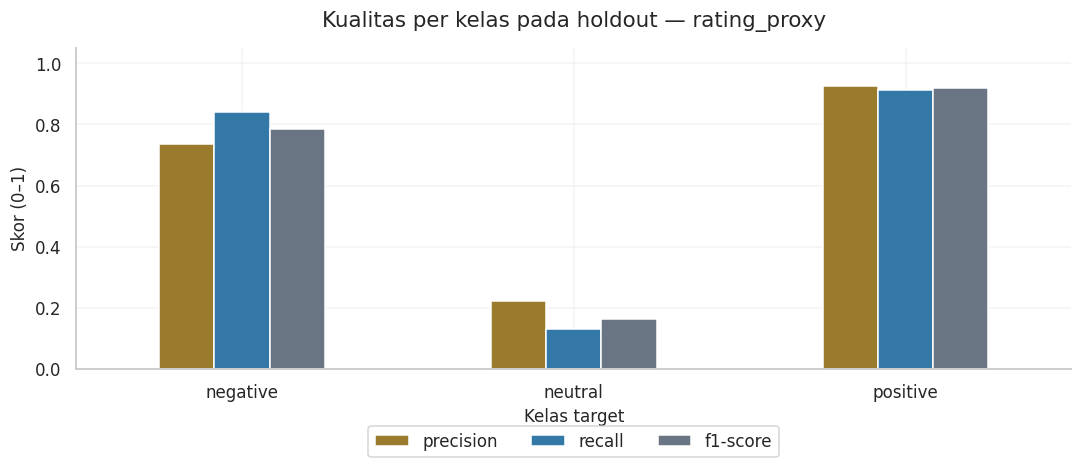

**Perlu ditinjau:** recall terendah ada pada kelas **neutral** (13.1%, support=107). Ini diagnosis setelah evaluasi, bukan alasan mengubah model memakai test yang sama.

In [30]:
%%maintain_gov
class_quality = pd.DataFrame({label: report[label] for label in LABELS}).T
fig, ax = plt.subplots(figsize=(10, 4.5))
class_quality[["precision", "recall", "f1-score"]].plot.bar(ax=ax, color=["#9A7B2E", "#3478A8", "#697582"], rot=0)
ax.set(title=f"Kualitas per kelas pada holdout — {LABEL_MODE}", xlabel="Kelas target", ylabel="Skor (0–1)", ylim=(0, 1.05))
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.15), ncol=3)
save_show("19_per_class_quality", fig)
weakest_label = class_quality["recall"].idxmin()
note(f"**Perlu ditinjau:** recall terendah ada pada kelas **{weakest_label}** "
     f"({class_quality.loc[weakest_label, 'recall']:.1%}, support={int(class_quality.loc[weakest_label, 'support'])}). "
     "Ini diagnosis setelah evaluasi, bukan alasan mengubah model memakai test yang sama.")

### 20.1 Ketidakpastian dengan bootstrap kelompok test
Resampling dilakukan atas kelompok teks test, bukan baris independen. CI 95%
percentile mencerminkan variasi sampel test pada model tetap; bukan variasi
pelatihan ulang, bukan jaminan generalisasi, dan belum mengatasi kelompok
parafrasa yang tidak terdeteksi. Semua kelas target tetap masuk perhitungan F1.

Macro-F1 0.6229; CI95% bootstrap grup [0.5906, 0.6496]; B=300.


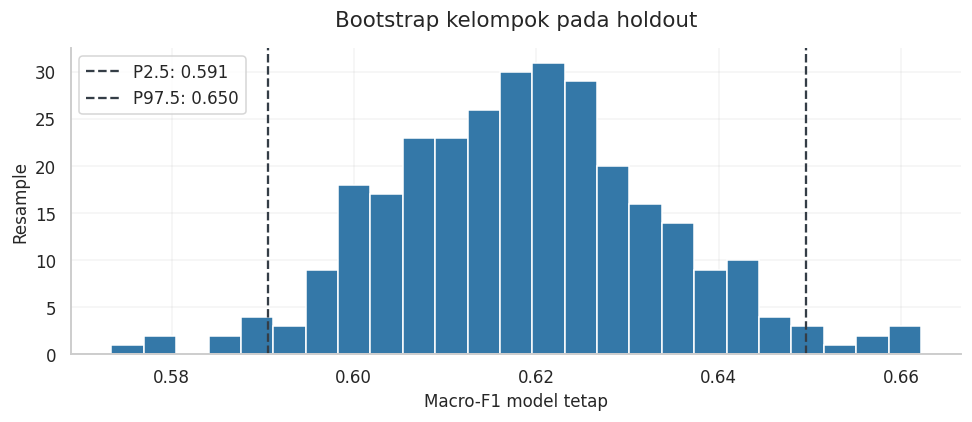

In [31]:
%%maintain_gov
group_positions = {key:np.flatnonzero(groups_test==key) for key in np.unique(groups_test)}
group_keys = list(group_positions)
bootstrap_f1 = []
bootstrap_rng = np.random.default_rng(SEED+2)
for _ in range(BOOTSTRAPS):
    selected_groups = bootstrap_rng.choice(group_keys,size=len(group_keys),replace=True)
    indices = np.concatenate([group_positions[key] for key in selected_groups])
    bootstrap_f1.append(f1_score(y_test[indices],y_pred[indices],labels=LABELS,average="macro",zero_division=0))
ci_low,ci_high = np.quantile(bootstrap_f1,[.025,.975])
print(f"Macro-F1 {test_metrics['macro_f1']:.4f}; CI95% bootstrap grup [{ci_low:.4f}, {ci_high:.4f}]; B={BOOTSTRAPS}.")
fig,ax = plt.subplots(figsize=(9,4))
ax.hist(bootstrap_f1,bins=25,color="#3478A8",edgecolor="white")
for value,label in [(ci_low,"P2.5"),(ci_high,"P97.5")]:
    ax.axvline(value,color="#343D46",linestyle="--",label=f"{label}: {value:.3f}")
ax.set(title="Bootstrap kelompok pada holdout",xlabel="Macro-F1 model tetap",ylabel="Resample")
ax.legend(); save_show("13_group_bootstrap",fig)

## 21. Precision–recall, kesalahan, dan audit sinyal lexicon
Decision score SVM/logistic adalah skor ranking, **bukan probabilitas terkalibrasi**.
Kurva one-vs-rest memberi konteks kelas langka; baseline garis putus-putus adalah
prevalensi kelas dalam test. Sel ini tidak memilih threshold deployment.

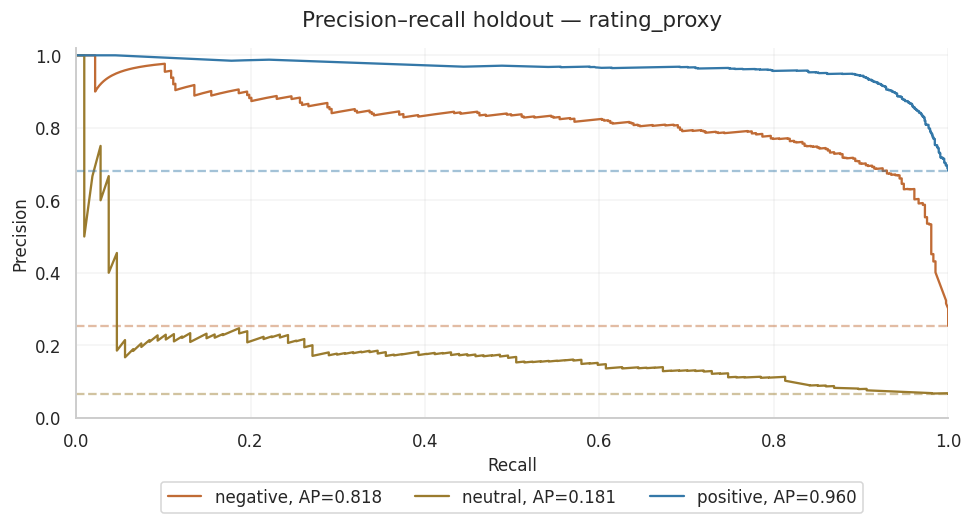

Jenis skor: decision score, bukan probabilitas


In [32]:
%%maintain_gov
if hasattr(final_model,"decision_function"):
    ranking_scores = final_model.decision_function(X_test)
    score_kind = "decision score, bukan probabilitas"
else:
    ranking_scores = final_model.predict_proba(X_test)
    score_kind = "probabilitas model; kalibrasi belum diuji"
if ranking_scores.ndim==1:
    ranking_scores = np.column_stack([-ranking_scores,ranking_scores])
model_classes = list(final_model.classes_)
fig,ax = plt.subplots(figsize=(9,5))
average_precision = {}
for position,label in enumerate(model_classes):
    truth_binary = (y_test==label).astype(int)
    precision,recall,_ = precision_recall_curve(truth_binary,ranking_scores[:,position])
    ap = average_precision_score(truth_binary,ranking_scores[:,position])
    average_precision[label] = float(ap)
    ax.plot(recall,precision,label=f"{label}, AP={ap:.3f}",color=COLORS.get(label,"#697582"))
    ax.axhline(truth_binary.mean(),color=COLORS.get(label,"#697582"),linestyle="--",alpha=.45)
ax.set(title=f"Precision–recall holdout — {LABEL_MODE}",xlabel="Recall",ylabel="Precision",xlim=(0,1),ylim=(0,1.02))
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.15),ncol=len(model_classes)); save_show("14_precision_recall",fig)
print("Jenis skor:",score_kind)

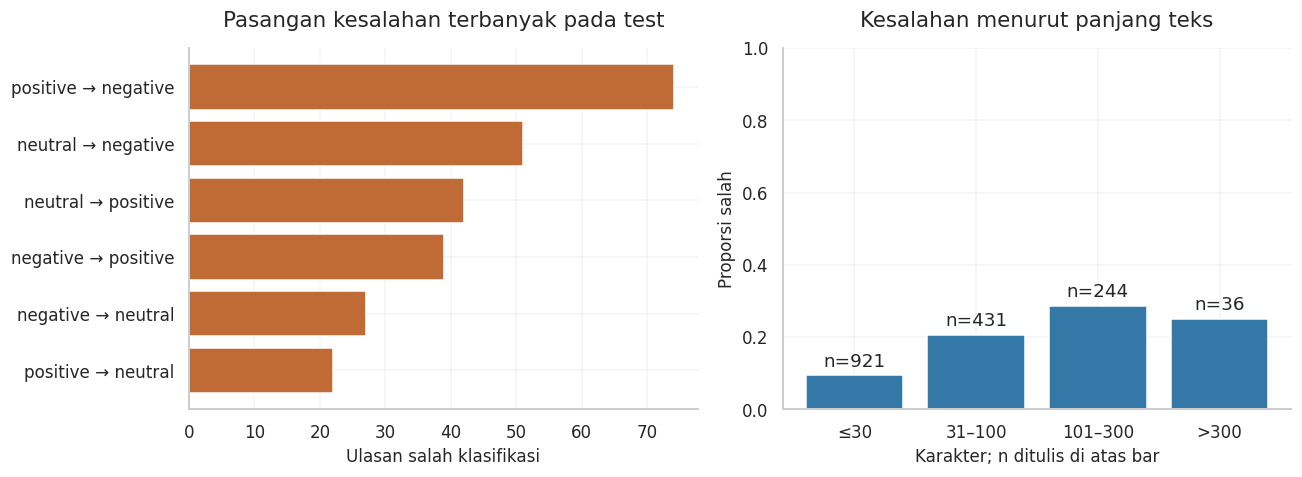

Lexicon output sebanding dengan vocabulary target: 949 / 1632
Agreement pada subset sebanding: 0.834


Agreement lexicon hanya memakai subset yang labelnya sebanding; mixed/undetermined yang tidak ada pada target tetap dihitung sebagai tidak tercakup, bukan diubah menjadi netral. Pada mode proksi, agreement terhadap rating tidak disebut akurasi sentimen manusia. Kesalahan per teks disimpan privat.

In [33]:
%%maintain_gov
errors = model_data.iloc[test_index][["reviewId","safe_source_text","target","rating_value","raw_length","text_group"]].copy()
errors["predicted"] = y_pred
errors["wrong"] = errors.target.ne(errors.predicted)
errors.to_csv(PRIVATE / "holdout_predictions_and_errors.csv",index=False,encoding="utf-8-sig")
error_counts = pd.crosstab(errors.target,errors.predicted).reindex(index=LABELS,columns=LABELS,fill_value=0)
for label in LABELS:
    error_counts.loc[label,label] = 0
fig,axes = plt.subplots(1,2,figsize=(12,4.5))
error_pairs = error_counts.stack().sort_values(ascending=False).head(6)
axes[0].barh([f"{left} → {right}" for left,right in error_pairs.index][::-1],error_pairs.values[::-1],color="#C06B35")
axes[0].set(title="Pasangan kesalahan terbanyak pada test",xlabel="Ulasan salah klasifikasi")
length_bins = pd.cut(errors.raw_length,bins=[-1,30,100,300,np.inf],labels=["≤30","31–100","101–300",">300"])
length_errors = errors.groupby(length_bins,observed=False).wrong.agg(["mean","size"])
axes[1].bar(length_errors.index.astype(str),length_errors["mean"].fillna(0),color="#3478A8")
axes[1].set(title="Kesalahan menurut panjang teks",xlabel="Karakter; n ditulis di atas bar",ylabel="Proporsi salah",ylim=(0,1))
for i,row in enumerate(length_errors.itertuples()):
    axes[1].text(i,(row.mean if pd.notna(row.mean) else 0)+.025,f"n={row.size}",ha="center")
save_show("15_error_analysis",fig)
lex_test = model_data.iloc[test_index].lexicon_label.to_numpy()
covered = np.isin(lex_test,LABELS)
lex_agreement = float((lex_test[covered]==y_test[covered]).mean()) if covered.any() else None
print("Lexicon output sebanding dengan vocabulary target:",int(covered.sum()),"/",len(lex_test))
print("Agreement pada subset sebanding:",round(lex_agreement,3) if lex_agreement is not None else "tidak tersedia")
note("Agreement lexicon hanya memakai subset yang labelnya sebanding; mixed/undetermined yang tidak ada "
     "pada target tetap dihitung sebagai tidak tercakup, bukan diubah menjadi netral. Pada mode proksi, "
     "agreement terhadap rating tidak disebut akurasi sentimen manusia. Kesalahan per teks disimpan privat.")

## 22. Pemeriksaan kebocoran, preprocessing, dan reproducibility
Pemeriksaan ini menguji logika implementasi. Lulusnya pemeriksaan bukan bukti
semua prediksi benar. Model tidak diubah berdasarkan hasil test.

In [34]:
%%maintain_gov
validation_checks = {}
validation_checks["train_test_group_overlap_zero"] = not bool(set(groups_train)&set(groups_test))
validation_checks["cv_group_overlap_zero"] = all(not set(groups_train[a])&set(groups_train[b]) for a,b in CV)
validation_checks["target_metadata_not_features"] = not bool(set(X.columns)&{"rating","rating_value","target","reviewId","userName","lexicon_score"})
validation_checks["negation_preserved"] = "tidak" in normalize_text("gak bisa login",SLANG).split()
validation_checks["unicode_case_whitespace"] = normalize_text("  BAGUS  ",SLANG)==normalize_text("bagus",SLANG)
validation_checks["email_masked"] = "@" not in normalize_text("kontak orang@example.com",SLANG)
validation_checks["long_number_masked"] = "081234567890" not in normalize_text("081234567890",SLANG)
validation_checks["overlap_lexicon_removed"] = not bool(set(LEXICON)&OVERLAP)
validation_checks["features_nonnegative"] = bool((X[NUMERIC_COLUMNS].to_numpy()>=0).all())
validation_checks["stable_prediction"] = bool(np.array_equal(y_pred,final_model.predict(X_test)))
validation_checks["finite_metrics"] = bool(np.isfinite(list(test_metrics.values())).all())
validation_checks["feature_dimension_matches"] = len(feature_names)==len(importance)
display(pd.Series(validation_checks,name="passed").to_frame())
assert all(validation_checks.values()),"Ada pemeriksaan yang gagal; jangan ekspor model sebagai tervalidasi."

,passed
train_test_group_overlap_zero,True
cv_group_overlap_zero,True
target_metadata_not_features,True
negation_preserved,True
unicode_case_whitespace,True
email_masked,True
long_number_masked,True
overlap_lexicon_removed,True
features_nonnegative,True
stable_prediction,True


## 23. Hubungkan hasil ke Maintenance Case MaintainGov
Sentimen tidak otomatis menentukan ada bug, kategori maintenance, severity,
atau prioritas. Bagian berikut memakai **aturan domain draf** yang sama dengan
baseline lokal: gagal login, crash, lambat, tulisan kecil, dan permintaan fitur.
Aturan dapat dikembangkan dari sampel development setelah review.

Satu issue utama dipilih menurut severity lalu key aturan. Jika beberapa issue
terdeteksi, hasil ditandai perlu pemeriksaan; ekstraksi multi-issue belum lengkap.
Teks tanpa aturan issue tidak diberi label bug hanya karena prediksi sentimennya
negatif. Pujian dan teks ambigu tetap dapat memerlukan review.

Prediksi seluruh dataset di sini **termasuk train dan test** untuk demonstrasi
output, sehingga grafik bagian ini bukan estimasi performa generalisasi.

In [35]:
%%maintain_gov
DOMAIN_RULES = json.loads('{"version": "rules-0.1-draft", "status": "draft_pending_team_review", "slang": {"gk": "tidak", "gak": "tidak", "ga": "tidak", "nggak": "tidak", "lemot": "lambat"}, "positive": ["bagus", "mudah", "mantap", "membantu", "lancar", "cepat"], "negative": ["buruk", "sulit", "susah", "lambat", "error", "gagal", "crash"], "negations": ["tidak", "bukan", "belum", "jangan"], "issues": [{"key": "login_failure", "category": "defect", "module": "autentikasi", "feature": "login", "severity": "high", "title": "Pengguna tidak dapat login", "phrases": ["tidak bisa login", "tidak dapat login", "gagal login", "tidak bisa masuk", "gagal masuk"], "recommendation": "Periksa alur autentikasi dan reproduksi kegagalan login menggunakan akun uji."}, {"key": "application_crash", "category": "defect", "module": "aplikasi", "feature": "stabilitas", "severity": "high", "title": "Aplikasi berhenti saat digunakan", "phrases": ["force close", "aplikasi crash", "keluar sendiri"], "recommendation": "Reproduksi langkah sebelum aplikasi berhenti dan periksa log error pada versi terkait."}, {"key": "slow_application", "category": "performance", "module": "aplikasi", "feature": "respons aplikasi", "severity": "medium", "title": "Respons aplikasi lambat", "phrases": ["lambat", "loading lama"], "recommendation": "Ukur waktu respons pada langkah yang dikeluhkan sebelum menentukan optimasi."}, {"key": "small_text", "category": "usability", "module": "antarmuka", "feature": "keterbacaan", "severity": "low", "title": "Tulisan sulit dibaca", "phrases": ["tulisan terlalu kecil", "huruf terlalu kecil"], "recommendation": "Tinjau ukuran teks dan uji keterbacaan pada ukuran layar yang relevan."}, {"key": "feature_request", "category": "request", "module": "belum_diketahui", "feature": "perlu klarifikasi", "severity": "low", "title": "Permintaan penambahan fitur", "phrases": ["tambah fitur", "tambahkan fitur"], "recommendation": "Klarifikasi kebutuhan dan pisahkan permintaan yang berbeda sebelum validasi case."}]}')
SEVERITY_VALUE = {"low":1,"medium":2,"high":3}
def domain_matches(tokens,phrase):
    words = phrase.split()
    return any(tokens[index:index+len(words)]==words and not is_negated(tokens,index)
               for index in range(len(tokens)-len(words)+1))
def domain_result(text):
    tokens = text.split()
    matches = [rule for rule in DOMAIN_RULES["issues"]
               if any(domain_matches(tokens,phrase) for phrase in rule["phrases"])]
    matches.sort(key=lambda rule:(-SEVERITY_VALUE[rule["severity"]],rule["key"]))
    rule = matches[0] if matches else None
    return {"rule_key":rule["key"] if rule else None,
            "category":rule["category"] if rule else "other",
            "severity":rule["severity"] if rule else None,
            "issue":rule["title"] if rule else None,
            "module":rule["module"] if rule else None,
            "feature":rule["feature"] if rule else None,
            "matched_rule_keys":[item["key"] for item in matches],
            "needs_manual_review":not rule or len(matches)>1 or rule["key"]=="feature_request"}
all_predictions = final_model.predict(features)
domain = pd.DataFrame([domain_result(text) for text in df.clean_text])
analysis_rows = pd.concat([df[["reviewId","clean_text","text_group","lexicon_label","lexicon_score"]].copy(),domain],axis=1)
analysis_rows["sentiment_model"] = all_predictions
analysis_rows["sentiment_target_mode"] = LABEL_MODE
analysis_rows["review_id"] = np.arange(1,len(analysis_rows)+1)
analysis_rows["disposition"] = np.where(analysis_rows.rule_key.notna(),"candidate_issue","needs_manual_review")
analysis_rows["case_group"] = None
print("Aturan domain:",DOMAIN_RULES["status"])
print("Ulasan dengan kandidat issue:",int(analysis_rows.rule_key.notna().sum()),"/",len(analysis_rows))

Aturan domain: draft_pending_team_review
Ulasan dengan kandidat issue: 227 / 7149


### 23.1 Grouping issue dengan kesamaan teks
Di dalam satu key aturan, TF-IDF cosine + average-linkage agglomerative clustering
mengelompokkan keluhan mirip. Threshold jarak 0,45 adalah draf; tidak dituning
dengan label test sentimen. Case berbeda kategori tidak digabung. Permintaan fitur
generik tetap terpisah per ulasan agar permintaan yang berbeda tidak tercampur.

Untuk kelompok >600 ulasan, dipakai exact-normalized-text grouping untuk membatasi
matriks jarak; ini fallback yang dapat terlalu memecah issue. ID sumber tetap
dipertahankan, sehingga frekuensi dihitung dari review ID berbeda. Hasil clustering
belum membuktikan kesamaan akar masalah. Silhouette (jika bisa dihitung) adalah
indikator struktur internal, bukan accuracy terhadap kelompok issue manusia.

In [36]:
%%maintain_gov
grouping_diagnostics = []
for key,subset in analysis_rows.loc[analysis_rows.rule_key.notna()].groupby("rule_key"):
    positions = subset.index.to_numpy()
    if key=="feature_request":
        cluster_ids = np.arange(len(subset)); method="one_request_per_review"
    elif len(subset)==1:
        cluster_ids = np.zeros(1,dtype=int); method="singleton"
    elif not RUN_GROUPING or len(subset)>600:
        cluster_ids = pd.factorize(subset.text_group,sort=True)[0]; method="exact_text_fallback"
    else:
        vectorizer = TfidfVectorizer(ngram_range=(1,2),min_df=1,max_features=6000)
        matrix = vectorizer.fit_transform(subset.clean_text)

        if (matrix.getnnz(axis=1)==0).any():
            cluster_ids = pd.factorize(subset.text_group,sort=True)[0]; method="exact_zero_vector_fallback"
        else:
            cluster_ids = AgglomerativeClustering(n_clusters=None,distance_threshold=.45,
                metric="cosine",linkage="average").fit_predict(matrix.toarray())
            method="tfidf_cosine_average_linkage"
    for position,cluster in zip(positions,cluster_ids):
        analysis_rows.loc[position,"case_group"] = f"{key}:cluster_{int(cluster):04d}"
    grouping_diagnostics.append({"rule":key,"reviews":len(subset),"groups":len(set(cluster_ids)),"method":method})
display(pd.DataFrame(grouping_diagnostics))
def case_priority(severity,frequency):
    return round(100*(.7*SEVERITY_VALUE[severity]/3+.3*min(frequency/10,1)),2)
rule_lookup = {rule["key"]:rule for rule in DOMAIN_RULES["issues"]}
cases = []
for group,subset in analysis_rows.loc[analysis_rows.case_group.notna()].groupby("case_group"):
    rule = rule_lookup[subset.rule_key.iloc[0]]
    cases.append({"group_key":group,"member_review_ids":sorted(subset.review_id.astype(int).tolist()),
        "title":rule["title"],"summary":f"{len(subset)} ulasan cocok dengan aturan {rule['key']}; perlu review konteks.",
        "category":rule["category"],"severity":rule["severity"],"frequency":len(subset),
        "priority_score":case_priority(rule["severity"],len(subset)),
        "recommendation":rule["recommendation"],"recommendation_status":"suggestion_requires_validation",
        "proposed_status":"Pending","persisted":False})
cases.sort(key=lambda case:(-case["priority_score"],case["group_key"]))
assert sum(case["frequency"] for case in cases)==int(analysis_rows.rule_key.notna().sum())
case_table = pd.DataFrame(cases)
print("Calon case:",len(cases),"| seluruhnya belum tersimpan pada MySQL.")

,rule,reviews,groups,method
0,application_crash,61,61,tfidf_cosine_average_linkage
1,feature_request,4,4,one_request_per_review
2,login_failure,99,96,tfidf_cosine_average_linkage
3,slow_application,63,53,tfidf_cosine_average_linkage


Calon case: 214 | seluruhnya belum tersimpan pada MySQL.


## 24. Visualisasi keluaran MaintainGov dan pemeriksaan formula prioritas
Formula draf: 70% severity (low=1, medium=2, high=3) + 30% frekuensi yang jenuh
pada 10 ulasan. Contoh high dengan 1 ulasan = 73, dengan 2 = 76. Kenaikan satu
level severity pada frekuensi sama sekitar 23,33 poin; tambahan satu ulasan
sebelum jenuh menambah 3 poin. Rating dan sentimen tidak masuk formula.

Formula tidak memuat kebaruan data, kepentingan layanan atau verifikasi dampak
yang belum tersedia. Periksa sensitivity curve dan tinjau bobot bersama PO.
Grafik case menghitung kandidat hasil aturan, bukan pekerjaan yang sudah valid.

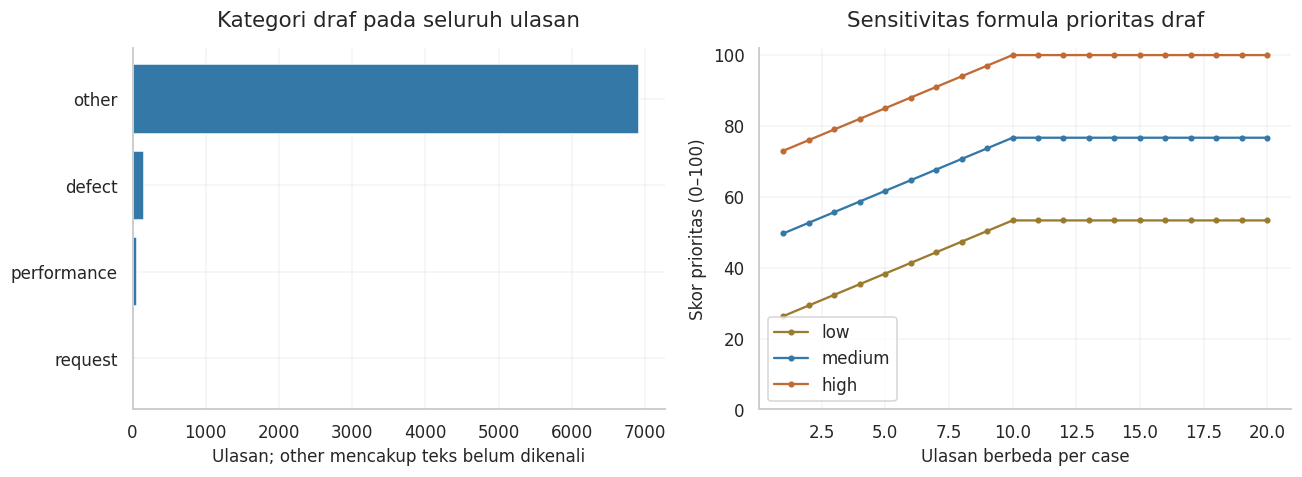

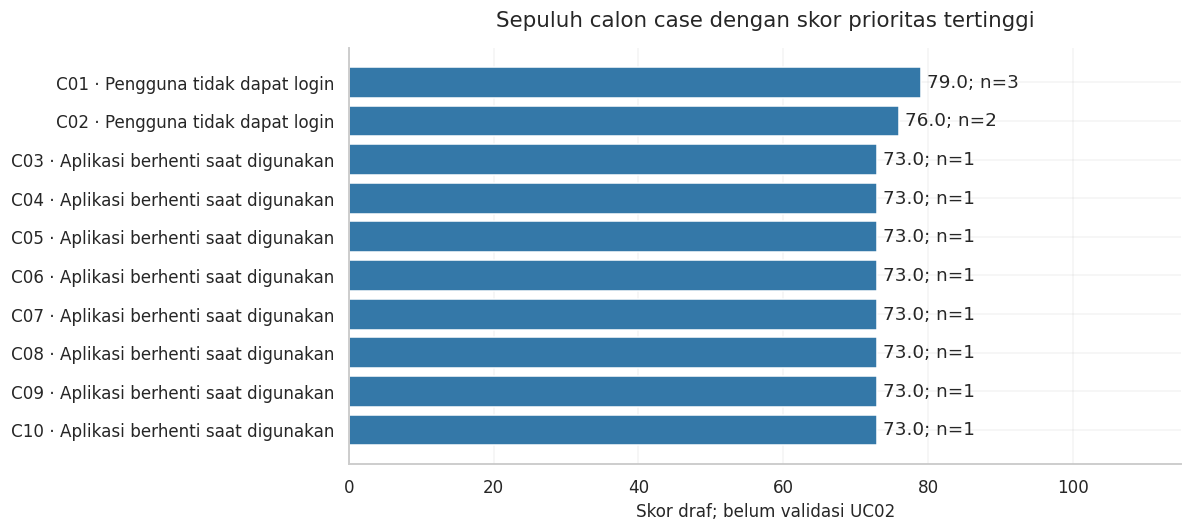

,label,category,severity,frequency,priority_score
0,C01 · Pengguna tidak dapat login,defect,high,3,79.0
1,C02 · Pengguna tidak dapat login,defect,high,2,76.0
2,C03 · Aplikasi berhenti saat digunakan,defect,high,1,73.0
3,C04 · Aplikasi berhenti saat digunakan,defect,high,1,73.0
4,C05 · Aplikasi berhenti saat digunakan,defect,high,1,73.0
5,C06 · Aplikasi berhenti saat digunakan,defect,high,1,73.0
6,C07 · Aplikasi berhenti saat digunakan,defect,high,1,73.0
7,C08 · Aplikasi berhenti saat digunakan,defect,high,1,73.0
8,C09 · Aplikasi berhenti saat digunakan,defect,high,1,73.0
9,C10 · Aplikasi berhenti saat digunakan,defect,high,1,73.0


In [37]:
%%maintain_gov
fig,axes = plt.subplots(1,2,figsize=(12,4.5))
category_counts = analysis_rows.category.value_counts()
axes[0].barh(category_counts.index[::-1],category_counts.values[::-1],color="#3478A8")
axes[0].set(title="Kategori draf pada seluruh ulasan",xlabel="Ulasan; other mencakup teks belum dikenali")
for severity,color in [("low","#9A7B2E"),("medium","#3478A8"),("high","#C06B35")]:
    frequencies = np.arange(1,21)
    axes[1].plot(frequencies,[case_priority(severity,int(n)) for n in frequencies],label=severity,color=color,marker="o",markersize=3)
axes[1].set(title="Sensitivitas formula prioritas draf",xlabel="Ulasan berbeda per case",ylabel="Skor prioritas (0–100)",ylim=(0,102))
axes[1].legend();save_show("16_maintain_categories_priority",fig)
if cases:
    top = case_table.head(10).copy()
    top["label"] = [f"C{i+1:02d} · {row.title}" for i,row in enumerate(top.itertuples())]
    fig,ax = plt.subplots(figsize=(11,5))
    bars = ax.barh(top.label[::-1],top.priority_score[::-1],color="#3478A8")
    ax.bar_label(bars,labels=[f"{score:.1f}; n={n}" for score,n in zip(top.priority_score[::-1],top.frequency[::-1])],padding=4)
    ax.set(title="Sepuluh calon case dengan skor prioritas tertinggi",xlabel="Skor draf; belum validasi UC02",xlim=(0,115))
    save_show("17_case_priority",fig)
    display(top[["label","category","severity","frequency","priority_score"]].round(2))
else:
    note("Tidak ada aturan domain yang cocok. Ini menunjukkan batas cakupan aturan, bukan bukti tidak ada masalah.")

## 25. Paket keluaran untuk Hanif dan Demas
Respons contoh mempertahankan ID ulasan, hasil per ulasan dan member case.
ID 1..N dalam notebook adalah **ID demo lokal**, bukan primary key database.
`source_id_map.csv` privat menautkannya ke reviewId sumber. Pada integrasi nyata,
Laravel menyimpan ulasan lebih dahulu dan mengirim ID internal yang benar.

Model artefak tetap model yang dilatih pada train split, sehingga skor holdout
merujuk model yang sama. Tidak otomatis refit ke seluruh data setelah melihat
test. Adapter harus menyamakan preprocessing, schema, dan label vocabulary.
`mixed` pada lexicon dan model human mungkin berbeda dari vocabulary proksi.

Output memiliki metadata riset tambahan; **belum kontrak final API kelompok**.
Hanif mereview sebelum menyambungkannya ke FastAPI/queue. Backend yang menetapkan
batch Selesai/Gagal, transaksi, retry idempoten, dan case Pending di MySQL.
Notebook tidak membuat backlog UC02 atau melakukan integrasi GitHub produk.

In [38]:
%%maintain_gov
RULES_SHA = hashlib.sha256(json.dumps(DOMAIN_RULES,sort_keys=True).encode()).hexdigest()
PREPROCESS_SHA = hashlib.sha256(PREPROCESS_SOURCE.encode()).hexdigest()
def as_jsonable(value):
    if isinstance(value,dict):
        return {str(key):as_jsonable(item) for key,item in value.items()}
    if isinstance(value,(list,tuple)):
        return [as_jsonable(item) for item in value]
    if isinstance(value,(np.integer,np.floating,np.bool_)):
        return value.item()
    if isinstance(value,np.ndarray):
        return value.tolist()
    return value
def write_json(path,value):
    path.write_text(json.dumps(as_jsonable(value),ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")
results_export = []
for row in analysis_rows.itertuples():
    results_export.append({"review_id":int(row.review_id),"category":row.category,
        "sentiment":row.sentiment_model,"sentiment_target_mode":LABEL_MODE,
        "sentiment_lexicon":row.lexicon_label,"severity":row.severity,
        "issue":row.issue,"module":row.module,"feature":row.feature,
        "group_key":row.case_group,"needs_manual_review":bool(row.needs_manual_review),
        "matched_rule_keys":row.matched_rule_keys,"disposition":row.disposition})
handoff = {"schema_version":"1.0","contract_status":"research_draft_requires_review",
    "analysis_version":f"colab-1.2-{RULES_SHA[:12]}","batch_id":101,
    "id_namespace":"notebook_demo_ids_replace_with_laravel_ids",
    "rules_status":"draft_pending_team_review","sentiment_target_mode":LABEL_MODE,
    "results":results_export,"cases":cases,
    "warnings":["Prediksi proksi rating bukan gold sentiment." if LABEL_MODE=="rating_proxy" else "Periksa provenance label manusia.",
                "Kategori/severity/priority masih aturan draf; case belum dipersistenkan.",
                "Model belum terintegrasi dengan Laravel/FastAPI/database."]}
write_json(PRIVATE/"maintain_gov_analysis.json",handoff)
analysis_rows[["review_id","reviewId"]].to_csv(PRIVATE/"source_id_map.csv",index=False)
write_json(PRIVATE/"slang_map.json",SLANG)
write_json(PRIVATE/"domain_rules.json",DOMAIN_RULES)
joblib.dump(final_model,PRIVATE/"sentiment_pipeline.joblib",compress=3)
reloaded = joblib.load(PRIVATE/"sentiment_pipeline.joblib")
assert np.array_equal(reloaded.predict(X_test),y_pred)
assert len(results_export)==len(df)
member_ids = [member for case in cases for member in case["member_review_ids"]]
assert len(member_ids)==len(set(member_ids)) and set(member_ids)<=set(analysis_rows.review_id)
print("Model round-trip dan keterlacakan anggota case: lolos.")

Model round-trip dan keterlacakan anggota case: lolos.


### 25.1 Contoh pemakaian artefak oleh layanan analisis
File joblib hanya dimuat dari artefak yang dibuat dan diperiksa sendiri; format
ini dapat mengeksekusi kode ketika dimuat. Contoh berikut ditulis ke paket privat
untuk handoff dan diuji pada kalimat sintetis. Package ini belum autentikasi
API, deployment, atau implementasi endpoint production.

In [39]:
%%maintain_gov
INFERENCE_SOURCE = r'''from pathlib import Path
import json
import joblib
from maintain_gov_preprocess import feature_frame

ROOT = Path(__file__).resolve().parent
MODEL = joblib.load(ROOT / "sentiment_pipeline.joblib")
SLANG = json.loads((ROOT / "slang_map.json").read_text(encoding="utf-8"))

def predict_sentiment(texts):
    if not isinstance(texts, (list, tuple)) or not texts or any(not isinstance(text,str) or not text.strip() for text in texts):
        raise ValueError("Input harus daftar teks tidak kosong.")
    return MODEL.predict(feature_frame(texts,SLANG)).tolist()
'''
(PRIVATE/"inference_example.py").write_text(INFERENCE_SOURCE,encoding="utf-8")
synthetic_texts = ["Tidak bisa login setelah pembaruan.","Bagus dan membantu pelayanan.","Aplikasi lambat saat dibuka."]
synthetic_features = feature_frame(synthetic_texts,SLANG)
synthetic_predictions = reloaded.predict(synthetic_features)
display(pd.DataFrame({"teks_sintetis":synthetic_texts,"prediksi":synthetic_predictions,"target_mode":LABEL_MODE}))

,teks_sintetis,prediksi,target_mode
0,Tidak bisa login setelah pembaruan.,negative,rating_proxy
1,Bagus dan membantu pelayanan.,positive,rating_proxy
2,Aplikasi lambat saat dibuka.,negative,rating_proxy


### 25.2 Smoke test artefak dalam proses Python baru
Memuat ulang joblib di kernel yang sama belum cukup: notebook mungkin tanpa
sengaja bergantung pada fungsi yang hanya ada di memori. Sel berikut mengimpor
modul hasil ekspor pada proses baru, membandingkan prediksinya, dan menguji
penolakan input kosong, string tunggal, nilai None dan elemen nonteks.
Contoh kalimat tetap sintetis dan bukan bukti akurasi sentimen.

In [40]:
%%maintain_gov
inference_probe = r"""import json
from inference_example import predict_sentiment
samples = ["Tidak bisa login setelah pembaruan.", "Bagus dan membantu pelayanan.", "Aplikasi lambat saat dibuka."]
invalid_inputs = [[], "teks tunggal", [""], [None], None, [12]]
rejected = []
for value in invalid_inputs:
    try:
        predict_sentiment(value)
    except ValueError:
        rejected.append(True)
    else:
        rejected.append(False)
print(json.dumps({"predictions": predict_sentiment(samples), "invalid_rejected": all(rejected)}))
"""
inference_result = subprocess.run([sys.executable, "-c", inference_probe], cwd=PRIVATE, capture_output=True, text=True)
if inference_result.returncode:
    print(inference_result.stderr[-4000:])
    raise RuntimeError("Modul inference hasil ekspor tidak dapat dijalankan dalam proses baru.")
fresh_inference = json.loads(inference_result.stdout)
artifact_smoke_checks = {
    "fresh_process_predictions_match": fresh_inference["predictions"] == synthetic_predictions.tolist(),
    "invalid_inference_inputs_rejected": fresh_inference["invalid_rejected"],
    "all_review_results_exported": len(results_export) == len(df),
    "case_members_unique": len(member_ids) == len(set(member_ids)),
    "case_members_traceable": set(member_ids) <= set(analysis_rows.review_id),
    "json_handoff_readable": json.loads((PRIVATE / "maintain_gov_analysis.json").read_text(encoding="utf-8"))["batch_id"] == 101,
    "negated_slow_not_issue": domain_result(normalize_text("aplikasi tidak lambat", SLANG))["rule_key"] is None,
    "synthetic_login_rule": domain_result(normalize_text("gak bisa login", SLANG))["rule_key"] == "login_failure",
}
display(pd.Series(artifact_smoke_checks, name="passed").to_frame())
assert all(artifact_smoke_checks.values()), "Smoke test artefak gagal."

,passed
fresh_process_predictions_match,True
invalid_inference_inputs_rejected,True
all_review_results_exported,True
case_members_unique,True
case_members_traceable,True
json_handoff_readable,True
negated_slow_not_issue,True
synthetic_login_rule,True


## 26. Rekap eksperimen, model card, dan ekspor
Paket hasil lengkap memuat dua ZIP:

- **Evidence agregat:** metrik, parameter, audit, fold, perbandingan dan grafik.
- **Artefak privat:** model, preprocessing, requirements, kamus, anotasi,
  prediksi per ulasan, karantina dan kandidat case.

Paket privat dan ZIP lengkap tetap di luar Git. Notebook hanya menampilkan
agregat dan contoh sintetis. Download hasil dimulai pada sel terakhir.


In [41]:
%%maintain_gov
metrics_bundle = {"notebook_version":"1.2", "target_mode":LABEL_MODE,"target_description":TARGET_DESCRIPTION,
    "source_sha256":SOURCE_SHA,"model_family":winner_name,"final_experiment":final_experiment,
    "test_rows":len(y_test),"test_groups":len(set(groups_test)),
    "train_rows":len(y_train),"train_groups":len(set(groups_train)),
    "metrics":test_metrics,"dummy_metrics":dummy_metrics,
    "macro_f1_group_bootstrap_ci95":[float(ci_low),float(ci_high)],"bootstrap_resamples":BOOTSTRAPS,
    "average_precision_per_class":average_precision,"classification_report":report,
    "lexicon_comparable_coverage":float(covered.mean()),"lexicon_subset_agreement":lex_agreement,
    "best_tuning_params":search.best_params_,"best_tuning_cv_macro_f1":float(search.best_score_),
    "cv_folds":n_folds,"search_iterations":SEARCH_ITER,"seed":SEED,
    "test_used_for_selection":False,"domain_rules_status":"draft_pending_team_review",
    "rules_sha256":RULES_SHA,"preprocess_sha256":PREPROCESS_SHA,
    "annotation_sha256":hashlib.sha256(annotation_bytes).hexdigest() if annotation_bytes else None,
    "source_url":SOURCE_URL,"source_license":SOURCE_LICENSE,
    "runtime_utc":RUN_STARTED,"runtime_versions":runtime_versions,"runtime_platform":platform.platform(),"python":platform.python_version(),"packages":PACKAGES,
    "limitations":["Rating proxy is not human sentiment ground truth.",
       "Duplicate grouping does not remove all paraphrases or same-user dependence.",
       "Dataset is historical snapshot; domain rules and labels require review.",
       "No end-to-end application, BDD, persistence or NFR load test acceptance."]}
write_json(PUBLIC/"metrics_and_provenance.json",metrics_bundle)
write_json(PUBLIC/"dataset_audit.json",audit)
write_json(PUBLIC/"validation_checks.json",validation_checks)
write_json(PUBLIC/"learning_curve.json",learning_result)
write_json(PUBLIC/"runtime_smoke_checks.json",runtime_smoke_checks)
write_json(PUBLIC/"artifact_smoke_checks.json",artifact_smoke_checks)
pd.DataFrame(fold_details).to_csv(PUBLIC/"cv_folds.csv",index=False)
comparison.to_csv(PUBLIC/"model_comparison.csv",index=False)
ablation.to_csv(PUBLIC/"feature_ablation.csv",index=False)
selection.to_csv(PUBLIC/"feature_selection_counts.csv",index=False)
tuning[["rank_test_score","mean_test_score","std_test_score","mean_train_score","mean_fit_time","params"]].to_csv(PUBLIC/"tuning_results.csv",index=False)
resource_audit.to_csv(PUBLIC/"resource_audit.csv",index=False)
requirements_text = "\n".join(f"{package}=={version}" for package,version in PACKAGES.items())+"\n"
(PRIVATE/"requirements.txt").write_text(requirements_text,encoding="utf-8")
model_card = f"""# MaintainGov sentiment experiment

Target: {TARGET_DESCRIPTION}. Mode: {LABEL_MODE}.
Model: {winner_name} / {final_experiment}. Train rows: {len(y_train)}.
Holdout rows: {len(y_test)}; grouped text overlap = 0.
Macro-F1: {test_metrics['macro_f1']:.4f}; group-bootstrap CI95% [{ci_low:.4f}, {ci_high:.4f}].
Balanced accuracy: {test_metrics['balanced_accuracy']:.4f}.

Best CV is a selection score, not independent test performance.
Rating-proxy performance must not be presented as accuracy against human sentiment.
Model vocabulary, parameters and corpus may encode source information; keep the model private until review.
Domain category, severity, grouping and priority are draft rules, not learned gold-label models.
Laravel/FastAPI/MySQL integration and PO acceptance are not verified by this notebook.

Source ZIP SHA256: {SOURCE_SHA}. Source license: {SOURCE_LICENSE}.
"""
(PUBLIC/"model_card.md").write_text(model_card,encoding="utf-8")
(PRIVATE/"model_card.md").write_text(model_card,encoding="utf-8")
public_zip = Path(shutil.make_archive(str(OUTPUT/"MaintainGov_evidence_agregat"),"zip",PUBLIC))
private_zip = Path(shutil.make_archive(str(OUTPUT/"MaintainGov_artefak_privat"),"zip",PRIVATE))
print("Paket tersedia:",public_zip.name,"dan",private_zip.name)
print("Jumlah gambar:",len(list(FIGURES.glob('*.png'))),"| Semua pemeriksaan logika:",all(validation_checks.values()))

Paket tersedia: MaintainGov_evidence_agregat.zip dan MaintainGov_artefak_privat.zip
Jumlah gambar: 19 | Semua pemeriksaan logika: True


### 26.1 Periksa isi paket sebelum download
Evidence hanya berisi agregat dan gambar. Model, anotasi dan prediksi per ulasan
berada pada paket privat. Pemeriksaan nama file di bawah membantu mencegah file
privat masuk paket evidence; tetap tinjau istilah pada grafik sebelum publikasi.

In [42]:
%%maintain_gov
zip_smoke_checks = {}
with zipfile.ZipFile(public_zip) as archive:
    public_names = set(archive.namelist())
    zip_smoke_checks["public_zip_integrity"] = archive.testzip() is None
    forbidden = {"sentiment_pipeline.joblib", "annotation_template.csv", "holdout_predictions_and_errors.csv", "maintain_gov_analysis.json", "source_id_map.csv"}
    zip_smoke_checks["private_files_not_in_public_zip"] = not any(PurePosixPath(name).name in forbidden for name in public_names)
    zip_smoke_checks["metrics_in_public_zip"] = "metrics_and_provenance.json" in public_names
with zipfile.ZipFile(private_zip) as archive:
    private_names = set(archive.namelist())
    zip_smoke_checks["private_zip_integrity"] = archive.testzip() is None
    zip_smoke_checks["inference_bundle_complete"] = {"sentiment_pipeline.joblib", "maintain_gov_preprocess.py", "inference_example.py", "slang_map.json", "requirements.txt"} <= private_names
display(pd.Series(zip_smoke_checks, name="passed").to_frame())
assert all(zip_smoke_checks.values()), "Pemeriksaan paket hasil gagal."
write_json(PUBLIC / "archive_smoke_checks.json", zip_smoke_checks)
write_json(PUBLIC / "artifact_inventory.json", {
    "evidence": [{"file": str(file.relative_to(PUBLIC)).replace("\\", "/"), "bytes": file.stat().st_size} for file in sorted(PUBLIC.rglob("*")) if file.is_file()],
    "private_file_count": len(private_names), "raw_dataset_in_evidence": False
})

public_zip = Path(shutil.make_archive(str(OUTPUT / "MaintainGov_evidence_agregat"), "zip", PUBLIC))
print("Paket hasil sudah diperiksa; simpan sebelum runtime berakhir.")

,passed
public_zip_integrity,True
private_files_not_in_public_zip,True
metrics_in_public_zip,True
private_zip_integrity,True
inference_bundle_complete,True


Paket hasil sudah diperiksa; simpan sebelum runtime berakhir.


## 27. Ringkasan hasil run dan langkah kelompok
Sel berikut menghitung ringkasan dari hasil aktual. Jangan menyebut aplikasi
selesai hanya karena notebook berhasil. Setelah label manusia tersedia, jalankan
ulang dengan mode human dan dokumentasikan perbedaan target, populasi dan split.

### Checklist setelah run

- **Eksperimen:** periksa semua tabel `passed`, model card, kelas dengan recall
  rendah, interval bootstrap, konflik kamus, dan error per ulasan secara privat.
- **Anotasi:** selesaikan label development dan test manusia melalui review;
  jalankan mode human pada file tersebut. Hindari berulang kali menyetel model
  berdasarkan test manusia yang sama.
- **Handoff Hanif:** serahkan requirements, preprocessing, slang map, pipeline,
  modul inference dan contoh respons riset. Uji lagi di lingkungan FastAPI.
- **Handoff Demas:** sepakati mapping ID sumber ke ID internal dan transaksi
  penyimpanan case Pending; ID demo notebook tidak boleh menjadi ID database.
- **Bukti kelompok:** commit notebook dan ringkasan agregat setelah pemeriksaan;
  kaitkan dengan W10-03/W10-07. Integrasi, demo, BDD dan penerimaan tetap dicatat
  terpisah dari keberhasilan eksperimen ini.

Untuk mengembangkan model berikutnya, prioritaskan label manusia dan cakupan
kelas minoritas sebelum menambah jumlah tuning. Evaluasi sumber/periode lain
merupakan eksperimen terpisah dengan test yang ditetapkan sebelum pelatihan.

In [43]:
%%maintain_gov
note(f"""
### Hasil yang tersedia pada run ini
- **{len(df):,} ulasan valid** dari ZIP; {len(quarantine)} record dikarantina.
- **Target model:** {TARGET_DESCRIPTION}.
- **Model:** {winner_name}, eksperimen {final_experiment}; {n_folds}-fold grouped CV, tuning {SEARCH_ITER} konfigurasi.
- **Holdout:** n={len(y_test):,}, macro-F1 **{test_metrics['macro_f1']:.3f}**, CI95% bootstrap grup **[{ci_low:.3f}, {ci_high:.3f}]**.
- **Sentimen lexicon:** {(df.lexicon_hits>0).mean():.1%} ulasan memiliki bukti kamus; tanpa bukti tetap undetermined.
- **Keluaran MaintainGov:** {len(cases)} calon case dari {analysis_rows.rule_key.notna().sum()} ulasan yang cocok aturan; belum validasi atau persistensi.

### Langkah Gerard sesudah eksperimen
1. Lengkapi provenance/lisensi sumber dan label manusia; periksa kesalahan serta konflik kamus bersama Demas/Valisha.
2. Review draf taxonomy, severity, grouping dan bobot prioritas pada D05; catat keputusan dan penyetuju.
3. Serahkan pipeline, preprocessing dan contoh payload kepada Hanif untuk W10-08, serta mapping ke Demas untuk W10-09.
4. Perbarui artefak UC01/PlantUML sesuai implementasi dan siapkan demo integrasi, BDD dan penerimaan PO.
5. Commit notebook dan evidence agregat yang sudah diperiksa pada branch tugas. Commit berikutnya berisi perubahan nyata: preprocessing, model/evaluasi atau perbaikan yang direview. Dataset dan paket privat tetap di luar Git.

**Belum dapat diklaim:** akurasi sentimen manusia pada mode proksi; kualitas model kategori/severity tanpa label; aplikasi end-to-end; target performa SRS; status Done atau penerimaan PO.
""")


### Hasil yang tersedia pada run ini
- **7,149 ulasan valid** dari ZIP; 0 record dikarantina.
- **Target model:** label proksi rating; belum gold sentiment.
- **Model:** LogisticRegression, eksperimen Tuned; 3-fold grouped CV, tuning 12 konfigurasi.
- **Holdout:** n=1,632, macro-F1 **0.623**, CI95% bootstrap grup **[0.591, 0.650]**.
- **Sentimen lexicon:** 75.0% ulasan memiliki bukti kamus; tanpa bukti tetap undetermined.
- **Keluaran MaintainGov:** 214 calon case dari 227 ulasan yang cocok aturan; belum validasi atau persistensi.

### Langkah Gerard sesudah eksperimen
1. Lengkapi provenance/lisensi sumber dan label manusia; periksa kesalahan serta konflik kamus bersama Demas/Valisha.
2. Review draf taxonomy, severity, grouping dan bobot prioritas pada D05; catat keputusan dan penyetuju.
3. Serahkan pipeline, preprocessing dan contoh payload kepada Hanif untuk W10-08, serta mapping ke Demas untuk W10-09.
4. Perbarui artefak UC01/PlantUML sesuai implementasi dan siapkan demo integrasi, BDD dan penerimaan PO.
5. Commit notebook dan evidence agregat yang sudah diperiksa pada branch tugas. Commit berikutnya berisi perubahan nyata: preprocessing, model/evaluasi atau perbaikan yang direview. Dataset dan paket privat tetap di luar Git.

**Belum dapat diklaim:** akurasi sentimen manusia pada mode proksi; kualitas model kategori/severity tanpa label; aplikasi end-to-end; target performa SRS; status Done atau penerimaan PO.


## Referensi metode dan acuan proyek
Dokumentasi berikut menjadi rujukan implementasi, bukan sumber label dataset.
Versi paket notebook dikunci; tautan metode scikit-learn memakai versi 1.6.

- [StratifiedGroupKFold](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html): stratifikasi dengan grup terpisah.
- [Data leakage dan pipeline](https://scikit-learn.org/1.6/common_pitfalls.html): fit preprocessing pada train/fold saja.
- [TF-IDF](https://scikit-learn.org/1.6/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html): word/character representation.
- [SelectPercentile](https://scikit-learn.org/1.6/modules/generated/sklearn.feature_selection.SelectPercentile.html): univariate feature ranking.
- [RandomizedSearchCV](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.RandomizedSearchCV.html): pencarian parameter melalui CV.
- [Classification report](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.classification_report.html): precision, recall, F1 dan support.
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html): notebook, penyimpanan dan batas runtime.
- Acuan kelompok: `docs/MASTERPLAN.md`, `docs/WEEK10_EXECUTION.md`, `docs/ARCHITECTURE.md`, `docs/DATASET_READINESS.md`, SRS FR-UC01-01..18. Lokasi ini adalah path repo, bukan dependensi runtime notebook.
- Sumber dataset: Kaggle menurut pemilik ZIP; URL, pembuat, versi, dan lisensi belum dilengkapi. Hash input dicatat setiap run.

### Menjalankan ulang
Unggah ZIP yang sama melalui Run all untuk mengulang eksperimen. Hash sumber,
parameter dan versi paket dicatat setiap run. Runtime Colab bersifat sementara;
simpan notebook dan paket hasil sebelum runtime berakhir.


## 28. Unduh hasil lengkap
ZIP lengkap berisi evidence agregat dan artefak privat. Unduhan dimulai otomatis setelah seluruh pemeriksaan selesai.

In [45]:
from IPython.display import FileLink
import zipfile
_mg_public_zip = _mg_run_dir / "MaintainGov_evidence_agregat.zip"
_mg_private_zip = _mg_run_dir / "MaintainGov_artefak_privat.zip"
_mg_complete_zip = _mg_run_dir / "MaintainGov_hasil_lengkap.zip"
with zipfile.ZipFile(_mg_complete_zip, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    archive.write(_mg_public_zip, _mg_public_zip.name)
    archive.write(_mg_private_zip, _mg_private_zip.name)
    archive.writestr("PANDUAN_HASIL.txt", "Evidence agregat berisi metrik dan grafik. Artefak privat berisi model, anotasi dan hasil per ulasan; simpan privat dan jangan unggah paket lengkap ke GitHub. Notebook eksperimen tidak menggantikan pengujian aplikasi Laravel/FastAPI/MySQL.")
with zipfile.ZipFile(_mg_complete_zip) as archive:
    assert archive.testzip() is None
display(FileLink(str(_mg_complete_zip), result_html_prefix="Hasil lengkap: "))
try:
    from google.colab import files
except ImportError:
    print("Paket hasil tersedia:", _mg_complete_zip)
else:
    files.download(str(_mg_complete_zip))
_mg_close()

C:\Users\LENOVO\OneDrive\Dokumen\ChatGPT\PPL PRAK FIX\tmp\smoke_v12_py313_clean\artifacts\MaintainGov_hasil_lengkap.zip